# Hackathon 7 — Sistema multi-agente con Groq
## Caso 3: Planificador logístico de última milla en Lima

| | |
|---|---|
| **Curso** | Programa de IA — Semana 9 |
| **Grupo** | [Nombre del grupo] |
| **Integrantes** | Luis Anthony Romero Padilla · Andrés Martin Benjamín Torres Ramos |
| **Caso seleccionado** | Caso 3 — Planificador logístico |
| **Fecha de entrega** | [octubre 2026] |
| **Motor LLM** | Groq — `openai/gpt-oss-20b` y `openai/gpt-oss-120b` |
| **Framework** | CrewAI (proceso secuencial + replanificación condicional) |

**Contenido:** 1. Introducción del caso · 2. Configuración del entorno · 3. Datos del caso · 4. Diseño de agentes · 5. Flujo de orquestación · 6. Implementación · 7–8. Resultados (escenarios A y B) · 9. Decisión final · 10. Tokens y costos · 11. Evaluación crítica · 12. Conclusiones

## 1. Introducción del caso

**Contexto.** *Distribuidora Andina* (empresa ficticia) abastece bodegas y minimarkets de Lima desde un almacén en **Ate**. Cada mañana el jefe de despacho tiene entre 15 y 20 pedidos repartidos en 7 distritos (La Molina, SJL, Surco, San Isidro, Miraflores, Barranco y Callao), una flota pequeña (2 furgones y 1 camioneta) y poco tiempo para decidir qué vehículo atiende qué pedidos y en qué orden.

| Pregunta | Respuesta |
|---|---|
| **¿Cuál es el problema?** | Asignar pedidos a vehículos y ordenar las paradas respetando capacidad, ventanas horarias de los clientes, la hora punta limeña y el fin del turno. Hoy se hace "a ojo" en una hoja de cálculo. |
| **¿Por qué es importante?** | En última milla el transporte puede ser la mayor parte del costo logístico, y un pedido de alta prioridad entregado tarde significa una bodega sin stock y un cliente insatisfecho. Lima, además, castiga mucho los malos cruces de ciudad (p. ej., Callao ↔ La Molina). |
| **¿Qué decisión se busca apoyar?** | Qué **estrategia de reparto del día** usar: asignación vehículo → secuencia de pedidos, incluyendo si conviene un segundo viaje con recarga. |
| **¿Quién usará el sistema?** | El **jefe de despacho** (usuario principal) antes de la salida de las 08:00, y el **supervisor de operaciones** cuando hay imprevistos (vehículo averiado, pedidos urgentes). |
| **¿Qué impacto tendría?** | Reducir el tiempo de planificación de ~45 min a pocos minutos, hacer comparables varias alternativas con cifras verificables y dejar trazabilidad de por qué se eligió un plan. **No reemplaza** al jefe de despacho: el plan siempre se revisa antes de ejecutarse. |

**Criterios de decisión** (en orden): 1) factibilidad —capacidad, turno, todos los pedidos asignados—; 2) cero pedidos de alta prioridad fuera de ventana; 3) el objetivo del día que fije la gerencia (costo o nivel de servicio); 4) menor riesgo operativo.

## 2. Configuración del entorno

Ejecutamos **localmente en Jupyter** con un entorno virtual de **Python 3.12** (CrewAI aún no soporta 3.14). Instalación, una sola vez desde la carpeta `entrega/`:

```bash
uv venv --python 3.12 .venv
uv pip install --python .venv -r requirements.txt
.venv\Scripts\python -m ipykernel install --user --name hackathon7
```

> En `requirements.txt` las versiones van dentro del archivo. Si se instalan desde una celda hay que poner comillas (`%pip install "crewai>=1.0"`). Sin comillas, la shell toma `>` como una redirección y no instala la versión pedida (este error estaba en los notebooks de la Semana 9).

In [1]:
import os, re, json, time, math, random, unicodedata
from collections import Counter
from pathlib import Path
from getpass import getpass

import pandas as pd
from dotenv import load_dotenv
from IPython.display import display, Markdown

# Antivirus como Kaspersky inspeccionan HTTPS con su propio certificado raíz (instalado en Windows).
# Python usa su propia lista (certifi) y rechaza esas conexiones de forma intermitente
# (CERTIFICATE_VERIFY_FAILED). truststore hace que Python confíe en el almacén de Windows, igual que el navegador.
import truststore
truststore.inject_into_ssl()

# Sin trazas ni telemetría hacia servidores de CrewAI: los prompts contienen datos de la operación
os.environ["CREWAI_TRACING_ENABLED"] = "false"
os.environ["CREWAI_DISABLE_TELEMETRY"] = "true"
os.environ["OTEL_SDK_DISABLED"] = "true"

import crewai, groq, litellm
print("CrewAI:", crewai.__version__, "| groq SDK:", groq.__version__)

CARPETA = Path.cwd()
EVIDENCIAS = CARPETA / "evidencias"
EVIDENCIAS.mkdir(exist_ok=True)

CrewAI: 1.15.27 | groq SDK: 1.7.0


### 2.1 Gestión de la API key de Groq

Reglas que seguimos (la rúbrica evalúa la gestión de las API keys para la demo en vivo):

1. **La key nunca se escribe en el notebook.** Se lee del archivo `.env`, que no se entrega ni se sube a ningún repositorio (está en `.gitignore`). Si el archivo no existe, se pide con `getpass`, que no deja rastro en las salidas.
2. Hay una **key de respaldo** (`GROQ_API_KEY_RESPALDO`, de otro integrante). Si la principal agota su cuota diaria durante la demo, basta con cambiar `USAR_RESPALDO = True` y volver a ejecutar esta celda.
3. Solo se muestran los **últimos 4 caracteres** para saber qué key está activa.
4. Antes de la demo se revisa la cuota restante en las cabeceras `x-ratelimit-*` que devuelve Groq (celda 2.2).
5. Las pruebas preliminares se hicieron con **Ollama** (`PROVEEDOR = "ollama"`) para no gastar la capa gratuita.

In [2]:
load_dotenv(CARPETA / ".env")

PROVEEDOR = os.getenv("PROVEEDOR_LLM", "groq")   # "groq" para la demo | "ollama" solo para pruebas locales
USAR_RESPALDO = False                           # True -> usa GROQ_API_KEY_RESPALDO


def obtener_api_key(usar_respaldo: bool = False) -> str:
    nombre = "GROQ_API_KEY_RESPALDO" if usar_respaldo else "GROQ_API_KEY"
    key = os.getenv(nombre, "").strip()
    if not key:
        key = getpass(f"{nombre} no está en .env. Pégala aquí (no se mostrará): ").strip()
    if not key.startswith("gsk_"):
        raise ValueError(f"{nombre} no parece una API key de Groq (debe empezar con 'gsk_').")
    os.environ["GROQ_API_KEY"] = key   # LiteLLM/CrewAI la leen de aquí
    return key


if PROVEEDOR == "groq":
    GROQ_API_KEY = obtener_api_key(USAR_RESPALDO)
    print(f"Proveedor: Groq | key activa: ...{GROQ_API_KEY[-4:]} | respaldo: {USAR_RESPALDO}")
else:
    GROQ_API_KEY = None
    print("Proveedor: Ollama local (solo pruebas; la demo se hace con Groq)")

Proveedor: Groq | key activa: ...7Ew8 | respaldo: False


### 2.2 Prueba directa de la API de Groq y cuota disponible

Antes de usar CrewAI llamamos a Groq directamente, sin framework, para comprobar que la key y el modelo responden. También leemos las cabeceras de *rate limit*. En el plan gratuito, `gpt-oss-20b` y `gpt-oss-120b` tienen un límite de **tokens por minuto (TPM)** bajo, y eso condicionó el diseño (ver sección 4.3).

In [3]:
MODELO_RAPIDO = "openai/gpt-oss-20b"      # analista y evaluador (tareas apoyadas en herramientas)
MODELO_RAZONADOR = "openai/gpt-oss-120b"  # planificador y decisor (más razonamiento)

if PROVEEDOR == "groq":
    from groq import Groq
    cliente = Groq(api_key=GROQ_API_KEY)
    for modelo in (MODELO_RAPIDO, MODELO_RAZONADOR):
        crudo = cliente.chat.completions.with_raw_response.create(
            model=modelo,
            messages=[{"role": "user", "content": "Responde solo: OK"}],
            max_tokens=20,
        )
        respuesta = crudo.parse()
        h = crudo.headers
        print(f"{modelo:22s} -> {respuesta.choices[0].message.content!r:8s} | "
              f"tokens/min restantes: {h.get('x-ratelimit-remaining-tokens')} de {h.get('x-ratelimit-limit-tokens')} | "
              f"requests/día restantes: {h.get('x-ratelimit-remaining-requests')} de {h.get('x-ratelimit-limit-requests')}")
else:
    print("Prueba de Groq omitida (PROVEEDOR = 'ollama').")

openai/gpt-oss-20b     -> ''       | tokens/min restantes: 7904 de 8000 | requests/día restantes: 964 de 1000


openai/gpt-oss-120b    -> ''       | tokens/min restantes: 7904 de 8000 | requests/día restantes: 985 de 1000


### 2.3 Configuración de los LLM en CrewAI

- `temperature` baja (0.1–0.2): queremos planes reproducibles, no creatividad.
- `reasoning_effort="low"` en todos los agentes. **Esta decisión salió de las pruebas:** con *medium*, `gpt-oss-120b` gastaba los 5 000 tokens de salida solo en razonar en el escenario B (`finish_reason=length`) y devolvía una respuesta vacía. No podemos subir más `max_tokens`, porque Groq rechaza una llamada si el prompt más `max_tokens` supera el límite de 8 000 tokens por minuto. Con *low*, el planificador resuelve el escenario B con unos 2 500 tokens, y como sus planes se **verifican con código**, una baja de calidad se detecta y se corrige con la replanificación.
- `max_tokens` por agente: planificador 4 500 (prompt ≈ 2 500 + salida 4 500 < 8 000) y decisor 3 500 (su prompt es mayor porque recibe planes y evaluación).
- `num_retries`: LiteLLM reintenta si Groq responde 429 (límite alcanzado).
- El parche de `mark_cache_breakpoint` es el mismo que usamos en clase: CrewAI marca los mensajes para caché de prompts y Groq rechaza ese campo extra.

In [4]:
import crewai.llms.cache as _crewai_cache
_crewai_cache.mark_cache_breakpoint = lambda msg: msg   # Groq no acepta el campo 'cache_breakpoint'

from crewai import Agent, Task, Crew, Process, LLM
from crewai.tools import tool

if PROVEEDOR == "groq":
    llm_rapido = LLM(model=f"groq/{MODELO_RAPIDO}", api_key=GROQ_API_KEY, temperature=0.1,
                     max_tokens=2500, reasoning_effort="low", num_retries=4)
    llm_razonador = LLM(model=f"groq/{MODELO_RAZONADOR}", api_key=GROQ_API_KEY, temperature=0.2,
                        max_tokens=4500, reasoning_effort="low", num_retries=4)    # planificador
    llm_decisor = LLM(model=f"groq/{MODELO_RAZONADOR}", api_key=GROQ_API_KEY, temperature=0.2,
                      max_tokens=3500, reasoning_effort="low", num_retries=4)      # decisor (prompt más largo)
    PAUSA_ENTRE_AGENTES = 20    # s: reparte el consumo dentro de la ventana de 1 minuto del TPM
    PAUSA_ENTRE_EJECUCIONES = 60
else:
    MODELO_RAPIDO = MODELO_RAZONADOR = "qwen3:14b"
    llm_rapido = llm_razonador = llm_decisor = LLM(model="ollama/qwen3:14b", base_url="http://localhost:11434", temperature=0.1)
    PAUSA_ENTRE_AGENTES = PAUSA_ENTRE_EJECUCIONES = 0

print("LLM rápido:", MODELO_RAPIDO, "| LLM razonador:", MODELO_RAZONADOR)

LLM rápido: openai/gpt-oss-20b | LLM razonador: openai/gpt-oss-120b


## 3. Datos del caso

Los datos son **sintéticos pero realistas** y los armamos nosotros: distancias y tiempos aproximados entre distritos de Lima en tráfico normal, ventanas horarias típicas de bodegas y una flota pequeña. Están en el notebook para que cualquiera pueda reproducir la ejecución.

**Reglas operativas** (las aplican las herramientas y también se informan a los agentes):
- Salida del almacén a las **08:00**. Todos los vehículos deben volver al almacén antes de las **19:00**.
- **10 min** de atención por pedido. Una recarga en el almacén toma **20 min**.
- **Hora punta** (08:00–09:30 y 17:30–19:30): los tiempos de viaje se multiplican por **1.4**.
- Si un vehículo llega antes de la ventana, **espera**. Si llega después, el pedido queda **fuera de ventana**.
- Un pedido **alta** fuera de ventana hace que el plan sea **infactible**. Un pedido **normal** fuera de ventana suma una penalidad de **S/ 30**.
- La carga entre dos salidas del almacén no puede superar la capacidad del vehículo.

In [5]:
REGLAS = {
    "inicio_turno": "08:00",
    "fin_turno": "19:00",
    "servicio_min": 10,
    "recarga_min": 20,
    "horas_punta": [("08:00", "09:30"), ("17:30", "19:30")],
    "factor_punta": 1.4,
    "penalidad_tarde_normal": 30,
}

NODOS = ["ALM", "La Molina", "SJL", "Surco", "San Isidro", "Miraflores", "Barranco", "Callao"]

# (km, minutos con tráfico normal) — aproximaciones para Lima, simétricas. ALM = almacén en Ate.
TRAMOS = {
    ("ALM", "La Molina"): (8, 20), ("ALM", "SJL"): (12, 30), ("ALM", "Surco"): (12, 30),
    ("ALM", "San Isidro"): (15, 35), ("ALM", "Miraflores"): (17, 40), ("ALM", "Barranco"): (19, 45),
    ("ALM", "Callao"): (28, 60),
    ("La Molina", "SJL"): (18, 45), ("La Molina", "Surco"): (8, 20), ("La Molina", "San Isidro"): (14, 35),
    ("La Molina", "Miraflores"): (15, 35), ("La Molina", "Barranco"): (15, 35), ("La Molina", "Callao"): (32, 70),
    ("SJL", "Surco"): (20, 45), ("SJL", "San Isidro"): (15, 40), ("SJL", "Miraflores"): (17, 45),
    ("SJL", "Barranco"): (20, 50), ("SJL", "Callao"): (20, 50),
    ("Surco", "San Isidro"): (8, 20), ("Surco", "Miraflores"): (7, 18), ("Surco", "Barranco"): (6, 15),
    ("Surco", "Callao"): (22, 50),
    ("San Isidro", "Miraflores"): (4, 12), ("San Isidro", "Barranco"): (7, 18), ("San Isidro", "Callao"): (14, 35),
    ("Miraflores", "Barranco"): (3, 10), ("Miraflores", "Callao"): (16, 40),
    ("Barranco", "Callao"): (18, 45),
}


def tramo(origen: str, destino: str) -> tuple:
    if origen == destino:
        return (1, 5)   # dos clientes en el mismo distrito
    return TRAMOS.get((origen, destino)) or TRAMOS[(destino, origen)]


def a_minutos(hora: str) -> int:
    hh, mm = hora.strip().split(":")
    return int(hh) * 60 + int(mm)


def a_hora(minutos: float) -> str:
    minutos = int(round(minutos))
    return f"{minutos // 60:02d}:{minutos % 60:02d}"


matriz = pd.DataFrame(
    [[f"{tramo(a, b)[1]} min / {tramo(a, b)[0]} km" if a != b else "—" for b in NODOS] for a in NODOS],
    index=NODOS, columns=NODOS)
display(matriz)

,ALM,La Molina,SJL,Surco,San Isidro,Miraflores,Barranco,Callao
ALM,—,20 min / 8 km,30 min / 12 km,30 min / 12 km,35 min / 15 km,40 min / 17 km,45 min / 19 km,60 min / 28 km
La Molina,20 min / 8 km,—,45 min / 18 km,20 min / 8 km,35 min / 14 km,35 min / 15 km,35 min / 15 km,70 min / 32 km
SJL,30 min / 12 km,45 min / 18 km,—,45 min / 20 km,40 min / 15 km,45 min / 17 km,50 min / 20 km,50 min / 20 km
Surco,30 min / 12 km,20 min / 8 km,45 min / 20 km,—,20 min / 8 km,18 min / 7 km,15 min / 6 km,50 min / 22 km
San Isidro,35 min / 15 km,35 min / 14 km,40 min / 15 km,20 min / 8 km,—,12 min / 4 km,18 min / 7 km,35 min / 14 km
Miraflores,40 min / 17 km,35 min / 15 km,45 min / 17 km,18 min / 7 km,12 min / 4 km,—,10 min / 3 km,40 min / 16 km
Barranco,45 min / 19 km,35 min / 15 km,50 min / 20 km,15 min / 6 km,18 min / 7 km,10 min / 3 km,—,45 min / 18 km
Callao,60 min / 28 km,70 min / 32 km,50 min / 20 km,50 min / 22 km,35 min / 14 km,40 min / 16 km,45 min / 18 km,—


### 3.1 Escenarios

Ejecutamos el sistema con **dos escenarios** para mostrar que responde a entradas distintas:

- **Escenario A — día normal.** 15 pedidos, 3 vehículos disponibles. Objetivo de la gerencia: **costo mínimo**.
- **Escenario B — día con imprevistos.** El furgón V2 está en mantenimiento y entran 2 pedidos urgentes. La demanda supera la capacidad de una sola salida, así que hace falta **recargar**. Objetivo: **nivel de servicio**.

In [6]:
PEDIDOS_BASE = [
    # id,   distrito,     kg,  ventana,        prioridad
    ("P01", "Miraflores", 120, "09:00-12:00", "alta"),
    ("P02", "Miraflores", 80,  "10:00-14:00", "normal"),
    ("P03", "San Isidro", 200, "09:00-11:00", "alta"),
    ("P04", "San Isidro", 150, "13:00-17:00", "normal"),
    ("P05", "Surco",      180, "08:30-12:00", "normal"),
    ("P06", "Surco",      90,  "14:00-18:00", "normal"),
    ("P07", "La Molina",  250, "08:30-10:30", "alta"),
    ("P08", "La Molina",  60,  "11:00-16:00", "normal"),
    ("P09", "SJL",        300, "09:00-13:00", "normal"),
    ("P10", "SJL",        120, "14:00-17:00", "normal"),
    ("P11", "Callao",     350, "10:00-15:00", "normal"),
    ("P12", "Callao",     100, "10:00-12:00", "alta"),
    ("P13", "Barranco",   70,  "11:00-14:00", "normal"),
    ("P14", "Barranco",   110, "15:00-18:00", "normal"),
    ("P15", "Miraflores", 60,  "15:00-18:00", "normal"),
]
COLUMNAS = ["id", "distrito", "kg", "ventana", "prioridad"]

FLOTA_BASE = [
    {"id": "V1", "tipo": "furgón",    "capacidad_kg": 1000, "costo_km": 1.8, "costo_hora": 20, "disponible": True},
    {"id": "V2", "tipo": "furgón",    "capacidad_kg": 1000, "costo_km": 1.8, "costo_hora": 20, "disponible": True},
    {"id": "V3", "tipo": "camioneta", "capacidad_kg": 600,  "costo_km": 1.2, "costo_hora": 18, "disponible": True},
]

ESCENARIO_A = {
    "nombre": "A - Día normal",
    "pedidos": [dict(zip(COLUMNAS, p)) for p in PEDIDOS_BASE],
    "flota": [dict(v) for v in FLOTA_BASE],
    "restricciones_extra": [],
    "objetivo": "Minimizar el costo total del día (S/) sin incumplir ningún pedido de prioridad alta.",
}

ESCENARIO_B = {
    "nombre": "B - Vehículo en mantenimiento + urgentes",
    "pedidos": [dict(zip(COLUMNAS, p)) for p in PEDIDOS_BASE] + [
        dict(zip(COLUMNAS, ("P16", "Callao",     150, "09:30-11:30", "alta"))),
        dict(zip(COLUMNAS, ("P17", "San Isidro", 90,  "10:00-12:00", "alta"))),
    ],
    "flota": [dict(v, disponible=(v["id"] != "V2")) for v in FLOTA_BASE],
    "restricciones_extra": ["V2 está en mantenimiento todo el día.",
                            "P16 y P17 son pedidos urgentes que entraron a las 07:30."],
    "objetivo": ("Priorizar el nivel de servicio: todos los pedidos de alta prioridad a tiempo y el menor número "
                 "de entregas fuera de ventana, aunque el costo suba."),
}

for esc in (ESCENARIO_A, ESCENARIO_B):
    df = pd.DataFrame(esc["pedidos"])
    disponibles = [v for v in esc["flota"] if v["disponible"]]
    print(f"\n{esc['nombre']}: {len(df)} pedidos, {df.kg.sum()} kg, "
          f"capacidad por salida {sum(v['capacidad_kg'] for v in disponibles)} kg ({len(disponibles)} vehículos)")
display(pd.DataFrame(ESCENARIO_B["pedidos"]).set_index("id").T)
display(pd.DataFrame(ESCENARIO_B["flota"]).set_index("id"))


A - Día normal: 15 pedidos, 2240 kg, capacidad por salida 2600 kg (3 vehículos)

B - Vehículo en mantenimiento + urgentes: 17 pedidos, 2480 kg, capacidad por salida 1600 kg (2 vehículos)


id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17
distrito,Miraflores,Miraflores,San Isidro,San Isidro,Surco,Surco,La Molina,La Molina,SJL,SJL,Callao,Callao,Barranco,Barranco,Miraflores,Callao,San Isidro
kg,120,80,200,150,180,90,250,60,300,120,350,100,70,110,60,150,90
ventana,09:00-12:00,10:00-14:00,09:00-11:00,13:00-17:00,08:30-12:00,14:00-18:00,08:30-10:30,11:00-16:00,09:00-13:00,14:00-17:00,10:00-15:00,10:00-12:00,11:00-14:00,15:00-18:00,15:00-18:00,09:30-11:30,10:00-12:00
prioridad,alta,normal,alta,normal,normal,normal,alta,normal,normal,normal,normal,alta,normal,normal,normal,alta,alta


,tipo,capacidad_kg,costo_km,costo_hora,disponible
id,,,,,
V1,furgón,1000,1.8,20,True
V2,furgón,1000,1.8,20,False
V3,camioneta,600,1.2,18,True


### 3.2 Prompt inicial: las 4 entradas del sistema

El sistema recibe un prompt inicial con **4 entradas** (el enunciado pide entre 2 y 5):

| Entrada | Contenido |
|---|---|
| `pedidos` | Un pedido por línea: `id;distrito;kg;ventana;prioridad` |
| `flota` | Vehículos, capacidad, costos y disponibilidad |
| `restricciones` | Reglas del turno y los imprevistos del día |
| `objetivo` | Qué prioriza hoy la gerencia (costo o nivel de servicio) |

El orquestador agrega dos campos internos que el usuario no llena: `retroalimentacion` (solo cuando se replanifica) y `diagnostico_previo`.

In [7]:
def entradas_del_escenario(esc: dict) -> dict:
    pedidos = "\n".join(f"{p['id']};{p['distrito']};{p['kg']};{p['ventana']};{p['prioridad']}" for p in esc["pedidos"])
    flota = "\n".join(
        f"{v['id']};{v['tipo']};capacidad {v['capacidad_kg']} kg;S/ {v['costo_km']} por km;S/ {v['costo_hora']} por hora;"
        + ("disponible" if v["disponible"] else "NO DISPONIBLE")
        for v in esc["flota"])
    reglas = [
        f"Salida del almacén (ALM, Ate) a las {REGLAS['inicio_turno']}; regreso obligatorio antes de las {REGLAS['fin_turno']}.",
        f"Atención: {REGLAS['servicio_min']} min por pedido. Recarga en almacén: {REGLAS['recarga_min']} min.",
        f"Hora punta {', '.join(a + '-' + b for a, b in REGLAS['horas_punta'])}: tiempos de viaje x{REGLAS['factor_punta']}.",
        "Un pedido de prioridad alta fuera de su ventana vuelve infactible el plan.",
        f"Pedido normal fuera de ventana: penalidad de S/ {REGLAS['penalidad_tarde_normal']}.",
        "La carga entre dos salidas del almacén no puede superar la capacidad del vehículo.",
    ] + esc["restricciones_extra"]
    return {
        "pedidos": pedidos,
        "flota": flota,
        "restricciones": "\n".join(f"- {r}" for r in reglas),
        "objetivo": esc["objetivo"],
    }


for clave, valor in entradas_del_escenario(ESCENARIO_A).items():
    print(f"=== {clave} ===\n{valor}\n")

=== pedidos ===
P01;Miraflores;120;09:00-12:00;alta
P02;Miraflores;80;10:00-14:00;normal
P03;San Isidro;200;09:00-11:00;alta
P04;San Isidro;150;13:00-17:00;normal
P05;Surco;180;08:30-12:00;normal
P06;Surco;90;14:00-18:00;normal
P07;La Molina;250;08:30-10:30;alta
P08;La Molina;60;11:00-16:00;normal
P09;SJL;300;09:00-13:00;normal
P10;SJL;120;14:00-17:00;normal
P11;Callao;350;10:00-15:00;normal
P12;Callao;100;10:00-12:00;alta
P13;Barranco;70;11:00-14:00;normal
P14;Barranco;110;15:00-18:00;normal
P15;Miraflores;60;15:00-18:00;normal

=== flota ===
V1;furgón;capacidad 1000 kg;S/ 1.8 por km;S/ 20 por hora;disponible
V2;furgón;capacidad 1000 kg;S/ 1.8 por km;S/ 20 por hora;disponible
V3;camioneta;capacidad 600 kg;S/ 1.2 por km;S/ 18 por hora;disponible

=== restricciones ===
- Salida del almacén (ALM, Ate) a las 08:00; regreso obligatorio antes de las 19:00.
- Atención: 10 min por pedido. Recarga en almacén: 20 min.
- Hora punta 08:00-09:30, 17:30-19:30: tiempos de viaje x1.4.
- Un pedido de 

## 4. Diseño de agentes

| # | Agente | Rol | Objetivo | Recibe | Produce | Tool | Modelo Groq |
|---|---|---|---|---|---|---|---|
| 1 | **Analista de operaciones** | Analista logístico | Convertir los datos del día en un diagnóstico cuantitativo | `pedidos`, `flota`, `restricciones`, `objetivo` | Carga por distrito, capacidad frente a demanda, pedidos críticos, agrupaciones y alertas de datos | `Resumen de operación por zona` | `gpt-oss-20b` |
| 2 | **Planificador** | Diseñador de rutas | Proponer **3 estrategias realmente distintas** | Diagnóstico + pedidos + flota + matriz de tiempos | Tres planes con formato estricto `PLAN E1 = V1: P07 > P05 ; V3: ...` | — | `gpt-oss-120b` |
| 3 | **Evaluador** | Analista de eficiencia | Comparar las estrategias **con números calculados, no estimados** | Las 3 estrategias | Tabla de costo, km, hora de regreso, entregas tarde, complejidad y riesgo | `Evaluar estrategias de reparto` | `gpt-oss-20b` |
| 4 | **Decisor** | Coordinador logístico | Elegir y justificar la estrategia final | Estrategias + evaluación | Decisión, criterios, riesgos, checklist para revisión humana y la línea `PLAN_FINAL` | — | `gpt-oss-120b` |

### 4.1 ¿Por qué 4 agentes y no 3 ni 5?
- **Con 3 agentes** tendríamos que unir planificador y evaluador. El mismo modelo juzgaría sus propias propuestas, y ese sesgo de autoevaluación es justo lo que queremos evitar. Separarlos crea un control cruzado: uno propone y otro mide con una herramienta.
- **Con 5 agentes** (por ejemplo, un "validador de datos" o un "redactor") gastaríamos más tokens sin ganar calidad. La validación de datos la hace **código Python determinista** antes de llamar al LLM, que es más barato y más confiable. Y el límite de tokens por minuto de Groq penaliza cada llamada adicional.
- Cada agente tiene **una sola responsabilidad**, y su salida es la entrada del siguiente. Esto hace que el flujo se pueda auditar.

### 4.2 Herramientas (tools)
Los LLM son malos sumando kilómetros y simulando horarios. Por eso **todo cálculo numérico lo hacen funciones Python deterministas** expuestas como tools de CrewAI (`@tool`):
- **`Resumen de operación por zona`** (usada por el Analista): agrega pedidos, kg, ventanas y tiempos desde el almacén por distrito, y calcula el número mínimo de salidas.
- **`Evaluar estrategias de reparto`** (usada por el Evaluador): simula minuto a minuto cada plan con hora punta, esperas, capacidad por viaje y fin de turno. Devuelve costo, km, hora de regreso, entregas tarde y la causa exacta de cualquier infactibilidad.

Esa misma función se reutiliza después para **verificar de forma independiente** el plan que elige el Decisor.

### 4.3 Selección del modelo (justificada con nuestra tabla comparativa de la Semana 9)
- La tabla *"Comparación de modelos"* clasifica **GPT-oss-20b** y **GPT-oss-120b** con *Function Calling: Supported* y *Reasoning: Higher*, con contexto de 131K tokens. Son los dos modelos de la tabla que **Groq sirve en producción**, y en Groq son baratos ($0.075/$0.30 y $0.15/$0.60 por millón de tokens de entrada/salida).
- El **20b** se encarga de las tareas que dependen de una tool (analista y evaluador): son tareas acotadas, y el modelo es rápido y barato.
- El **120b** se encarga de las tareas que más razonamiento exigen (planificar con restricciones y decidir).
- **Gestión del límite de TPM:** en el plan gratuito cada modelo tiene su propio límite de tokens por minuto. Alternar 20b → 120b → 20b → 120b reparte el consumo entre dos cuotas. Además hay una pausa corta entre agentes.
- Descartamos `qwen/qwen3.8-27b` (en Groq solo está en *preview*: puede retirarse sin aviso, y es más caro) y los modelos de Llama (no tienen razonamiento y su tool calling es menos fiable). El detalle está en `modelos_groq_recomendados.md`.

## 5. Diseño del flujo de orquestación

- **Tipo de flujo:** **secuencial** (`Process.sequential`) con un **ciclo condicional** de replanificación (como máximo 1 reintento).
- **Orden:** validación de datos (Python) → Analista → Planificador → Evaluador → Decisor → verificación independiente (Python).
- **Paso de información:** cada `Task` recibe por `context` la salida de las anteriores. El Planificador recibe el diagnóstico; el Evaluador, las estrategias; y el Decisor, las estrategias y la evaluación (necesita las primeras para copiar el plan elegido).
- **Condición:** si la verificación independiente encuentra que el `PLAN_FINAL` es infactible, el orquestador vuelve a ejecutar **solo** Planificador → Evaluador → Decisor. Les pasa la lista de problemas encontrados y reutiliza el diagnóstico, sin volver a llamar al Analista, para ahorrar tokens.
- **Integra la respuesta final:** el **Decisor**. El resultado se entrega al **jefe de despacho**, que es quien aprueba.

```mermaid
flowchart TD
    U[/"Prompt inicial: pedidos · flota · restricciones · objetivo"/] --> V{"Validación de datos (Python)"}
    V -- "errores" --> H1["Se detiene: un humano corrige los datos"]
    V -- "OK" --> A["1 · Analista de operaciones<br/>gpt-oss-20b + tool Resumen"]
    A -- "diagnóstico" --> P["2 · Planificador<br/>gpt-oss-120b"]
    P -- "3 estrategias (PLAN E1..E3)" --> E["3 · Evaluador<br/>gpt-oss-20b + tool Evaluar"]
    E -- "tabla comparativa" --> D["4 · Decisor<br/>gpt-oss-120b"]
    P -. "estrategias" .-> D
    D -- "PLAN_FINAL" --> X{"Verificación independiente (Python)"}
    X -- "infactible y reintentos < 1" --> P
    X -- "factible o sin reintentos" --> R[/"Plan recomendado + checklist"/]
    R --> H2["Jefe de despacho aprueba o ajusta"]
```

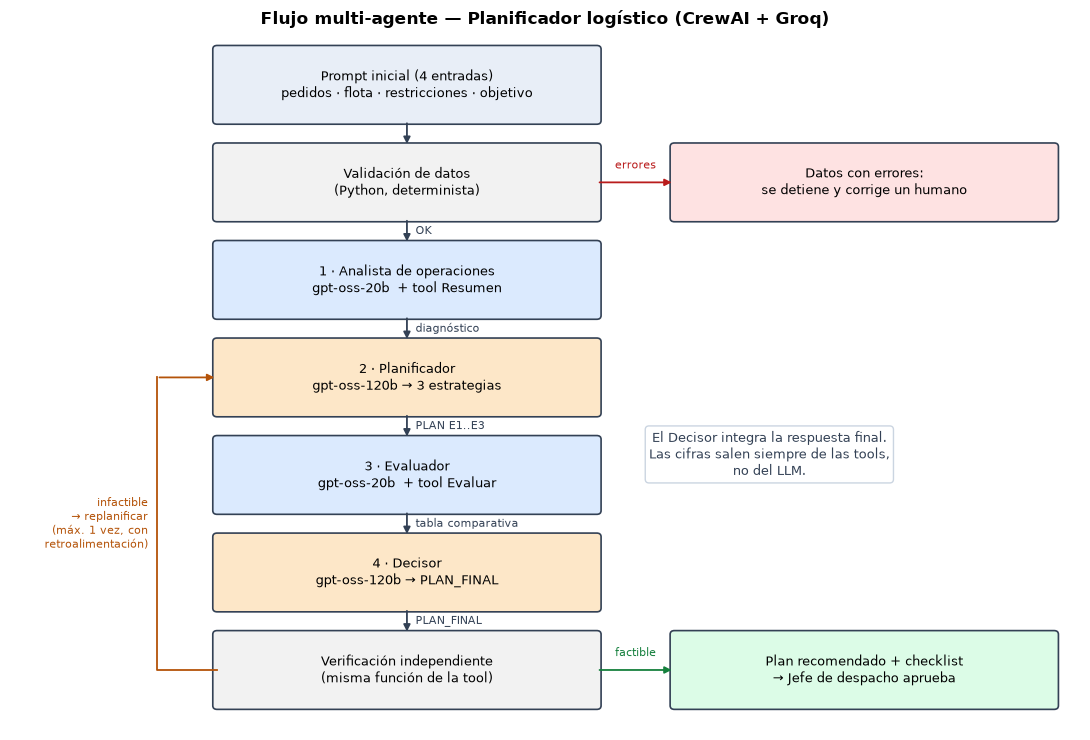

In [8]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def dibujar_diagrama(ruta_png):
    fig, ax = plt.subplots(figsize=(11, 7.5))
    ax.set_xlim(-1.6, 10.8); ax.set_ylim(0.4, 9.7); ax.axis("off")
    cajas = {
        "in":  (3.0, 9.0, "Prompt inicial (4 entradas)\npedidos · flota · restricciones · objetivo", "#e8eef7"),
        "val": (3.0, 7.7, "Validación de datos\n(Python, determinista)", "#f2f2f2"),
        "a":   (3.0, 6.4, "1 · Analista de operaciones\ngpt-oss-20b  + tool Resumen", "#dbeafe"),
        "p":   (3.0, 5.1, "2 · Planificador\ngpt-oss-120b → 3 estrategias", "#fde7c8"),
        "e":   (3.0, 3.8, "3 · Evaluador\ngpt-oss-20b  + tool Evaluar", "#dbeafe"),
        "d":   (3.0, 2.5, "4 · Decisor\ngpt-oss-120b → PLAN_FINAL", "#fde7c8"),
        "x":   (3.0, 1.2, "Verificación independiente\n(misma función de la tool)", "#f2f2f2"),
        "out": (8.3, 1.2, "Plan recomendado + checklist\n→ Jefe de despacho aprueba", "#dcfce7"),
        "stop":(8.3, 7.7, "Datos con errores:\nse detiene y corrige un humano", "#fee2e2"),
    }
    w, h = 4.4, 0.95
    for clave, (x, y, texto, color) in cajas.items():
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05",
                                    fc=color, ec="#334155", lw=1.2))
        ax.text(x, y, texto, ha="center", va="center", fontsize=9.5)

    def flecha(a, b, texto="", estilo="-|>", conn="arc3", color="#334155"):
        (x1, y1), (x2, y2) = a, b
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                    arrowprops=dict(arrowstyle=estilo, color=color, lw=1.3, connectionstyle=conn))
        if texto and y1 == y2:   # flecha horizontal: etiqueta encima
            ax.text((x1 + x2) / 2, y1 + 0.15, texto, fontsize=8, color=color, ha="center", va="bottom")
        elif texto:
            ax.text((x1 + x2) / 2 + 0.1, (y1 + y2) / 2, texto, fontsize=8, color=color, va="center")

    for s, t, lbl in [("in", "val", ""), ("val", "a", "OK"), ("a", "p", "diagnóstico"),
                      ("p", "e", "PLAN E1..E3"), ("e", "d", "tabla comparativa"), ("d", "x", "PLAN_FINAL")]:
        flecha((3.0, cajas[s][1] - h / 2), (3.0, cajas[t][1] + h / 2), lbl)
    flecha((5.2, 7.7), (6.1, 7.7), "errores", color="#b91c1c")
    flecha((5.2, 1.2), (6.1, 1.2), "factible", color="#15803d")
    izq = 3.0 - w / 2   # borde izquierdo de las cajas
    ax.plot([izq, 0.1, 0.1], [1.2, 1.2, 5.1], color="#b45309", lw=1.3)
    ax.annotate("", xy=(izq, 5.1), xytext=(0.1, 5.1),
                arrowprops=dict(arrowstyle="-|>", color="#b45309", lw=1.3))
    ax.text(0.0, 3.15, "infactible\n→ replanificar\n(máx. 1 vez, con\nretroalimentación)",
            fontsize=8, color="#b45309", ha="right", va="center")
    ax.text(7.2, 3.8, "El Decisor integra la respuesta final.\nLas cifras salen siempre de las tools,\nno del LLM.",
            fontsize=9, color="#334155", ha="center",
            bbox=dict(boxstyle="round", fc="white", ec="#cbd5e1"))
    ax.set_title("Flujo multi-agente — Planificador logístico (CrewAI + Groq)", fontsize=12, weight="bold")
    fig.tight_layout()
    fig.savefig(ruta_png, dpi=160)
    display(fig)
    plt.close(fig)

dibujar_diagrama(CARPETA / "diagrama_flujo.png")

## 6. Implementación

### 6.1 Motor de cálculo determinista
Es la base de las tools y de la verificación. Recibe un plan en texto, por ejemplo `V1: P07 > P05 > ALM > P09 ; V3: P12 > P11`, y lo **simula minuto a minuto**. No usa `eval`: el texto se interpreta con reglas estrictas y cualquier dato desconocido se reporta como error. Nunca se ejecuta lo que escribió el LLM.

In [9]:
def _limpiar(texto: str) -> str:
    return texto.replace("*", "").replace("`", "").replace("→", ">").strip()


def parsear_plan(texto_plan: str):
    """'V1: P07 > P05 ; V3: P11 > ALM > P12' -> ({'V1': ['P07','P05'], 'V3': ['P11','ALM','P12']}, errores)"""
    rutas, errores = {}, []
    for bloque in _limpiar(texto_plan).split(";"):
        if not bloque.strip():
            continue
        if ":" not in bloque:
            errores.append(f"Bloque sin vehículo: '{bloque.strip()}'")
            continue
        vehiculo, paradas = bloque.split(":", 1)
        vehiculo = vehiculo.strip().upper()
        tokens = [t.strip().upper() for t in re.split(r"->|>|,", paradas) if t.strip()]
        tokens = ["ALM" if t.startswith("ALM") else t for t in tokens]
        while tokens and tokens[0] == "ALM":
            tokens.pop(0)
        while tokens and tokens[-1] == "ALM":
            tokens.pop()
        if vehiculo in rutas:
            errores.append(f"{vehiculo} aparece dos veces en el plan")
        rutas.setdefault(vehiculo, []).extend(tokens)
    return rutas, errores


def _factor(t: float) -> float:
    en_punta = any(a_minutos(a) <= t < a_minutos(b) for a, b in REGLAS["horas_punta"])
    return REGLAS["factor_punta"] if en_punta else 1.0


def simular(rutas: dict, esc: dict, errores_previos=None) -> dict:
    pedidos = {p["id"]: p for p in esc["pedidos"]}
    flota = {v["id"]: v for v in esc["flota"]}
    inicio, fin_turno = a_minutos(REGLAS["inicio_turno"]), a_minutos(REGLAS["fin_turno"])
    errores, vehiculos, tarde, asignados = list(errores_previos or []), [], [], []

    for vid, paradas in rutas.items():
        v = flota.get(vid)
        if v is None:
            errores.append(f"Vehículo inexistente: {vid}")
            continue
        if not paradas:
            continue
        if not v["disponible"]:
            errores.append(f"{vid} no está disponible hoy")
            continue
        t, pos, km, espera, carga, carga_max, viajes = inicio, "ALM", 0.0, 0.0, 0.0, 0.0, 1
        for parada in paradas + ["FIN"]:
            if parada in ("ALM", "FIN"):
                d_km, d_min = tramo(pos, "ALM") if pos != "ALM" else (0, 0)
                t += d_min * _factor(t)
                km += d_km
                pos = "ALM"
                if carga > v["capacidad_kg"]:
                    errores.append(f"{vid} sobrecargado: {carga:.0f} kg en un viaje (capacidad {v['capacidad_kg']} kg)")
                carga_max, carga = max(carga_max, carga), 0.0
                if parada == "ALM":
                    t += REGLAS["recarga_min"]
                    viajes += 1
                continue
            p = pedidos.get(parada)
            if p is None:
                errores.append(f"Pedido inexistente en {vid}: {parada}")
                continue
            asignados.append(parada)
            d_km, d_min = tramo(pos, p["distrito"])
            t += d_min * _factor(t)
            km += d_km
            pos = p["distrito"]
            ini, fin = (a_minutos(x) for x in p["ventana"].split("-"))
            if t < ini:
                espera += ini - t
                t = ini
            if t > fin:
                tarde.append({"pedido": p["id"], "prioridad": p["prioridad"], "min_tarde": round(t - fin)})
            t += REGLAS["servicio_min"]
            carga += p["kg"]
        if t > fin_turno:
            errores.append(f"{vid} regresa a las {a_hora(t)}, después del fin de turno ({REGLAS['fin_turno']})")
        horas = (t - inicio) / 60
        vehiculos.append({
            "vehiculo": vid, "paradas": " > ".join(paradas), "km": round(km, 1),
            "regreso": a_hora(t), "horas": round(horas, 2), "espera_min": round(espera),
            "carga_max_viaje_kg": carga_max, "capacidad_kg": v["capacidad_kg"], "viajes": viajes,
            "costo": round(km * v["costo_km"] + horas * v["costo_hora"], 2),
        })

    duplicados = sorted(k for k, c in Counter(asignados).items() if c > 1)
    faltan = sorted(set(pedidos) - set(asignados))
    if duplicados:
        errores.append(f"Pedidos asignados más de una vez: {', '.join(duplicados)}")
    if faltan:
        errores.append(f"Pedidos sin asignar: {', '.join(faltan)}")
    alta_tarde = [x for x in tarde if x["prioridad"] == "alta"]
    if alta_tarde:
        errores.append("Alta prioridad fuera de ventana: "
                       + ", ".join(f"{x['pedido']} (+{x['min_tarde']} min)" for x in alta_tarde))
    n_normal_tarde = sum(1 for x in tarde if x["prioridad"] != "alta")
    penalidad = n_normal_tarde * REGLAS["penalidad_tarde_normal"]
    return {
        "factible": not errores,
        "errores": errores,
        "vehiculos": vehiculos,
        "tarde": tarde,
        "km_total": round(sum(v["km"] for v in vehiculos), 1),
        "regreso_mas_tarde": max((v["regreso"] for v in vehiculos), default="-"),
        "penalidad": penalidad,
        "costo_total": round(sum(v["costo"] for v in vehiculos) + penalidad, 2),
    }


def evaluar_plan(texto_plan: str, esc: dict) -> dict:
    rutas, errores = parsear_plan(texto_plan)
    return simular(rutas, esc, errores)


def formatear_resultado(nombre: str, r: dict) -> str:
    tarde = ", ".join(f"{x['pedido']}(+{x['min_tarde']}min,{x['prioridad']})" for x in r["tarde"]) or "ninguna"
    lineas = [f"{nombre}: {'FACTIBLE' if r['factible'] else 'INFACTIBLE'} | costo S/ {r['costo_total']:.2f} "
              f"(penalidades S/ {r['penalidad']}) | {r['km_total']} km | último regreso {r['regreso_mas_tarde']} "
              f"| fuera de ventana: {tarde}"]
    for v in r["vehiculos"]:
        lineas.append(f"  - {v['vehiculo']}: {v['km']} km, regreso {v['regreso']}, {v['viajes']} viaje(s), "
                      f"carga máx {v['carga_max_viaje_kg']:.0f}/{v['capacidad_kg']} kg, espera {v['espera_min']} min, "
                      f"S/ {v['costo']:.2f}")
    for e in r["errores"]:
        lineas.append(f"  ! {e}")
    return "\n".join(lineas)


# Prueba rápida del motor con un plan escrito a mano
plan_prueba = "V1: P07 > P08 > P05 > P06 ; V2: P03 > P01 > P02 > P13 > P04 > P15 > P14 ; V3: P12 > P11 > P09 > P10"
print(formatear_resultado("Plan de prueba", evaluar_plan(plan_prueba, ESCENARIO_A)))

Plan de prueba: INFACTIBLE | costo S/ 647.53 (penalidades S/ 0) | 148.0 km | último regreso 16:15 | fuera de ventana: ninguna
  - V1: 30.0 km, regreso 14:40, 1 viaje(s), carga máx 580/1000 kg, espera 270 min, S/ 187.33
  - V2: 56.0 km, regreso 16:15, 1 viaje(s), carga máx 790/1000 kg, espera 259 min, S/ 265.80
  - V3: 62.0 km, regreso 14:40, 1 viaje(s), carga máx 870/600 kg, espera 186 min, S/ 194.40
  ! V3 sobrecargado: 870 kg en un viaje (capacidad 600 kg)


### 6.2 Validación de datos antes de llamar al LLM
Es una **compuerta determinista**: si hay datos imposibles (distrito desconocido, peso inválido, ventana invertida o un pedido más pesado que cualquier vehículo), el sistema **no llama al LLM** y pide que un humano corrija los datos. Así evitamos que los agentes "rellenen" información faltante.

In [10]:
def validar_escenario(esc: dict) -> list:
    problemas = []
    disponibles = [v for v in esc["flota"] if v.get("disponible")]
    if not disponibles:
        problemas.append("No hay vehículos disponibles.")
    cap_max = max((v["capacidad_kg"] for v in disponibles), default=0)
    ids = [p.get("id") for p in esc["pedidos"]]
    for dup in sorted(k for k, c in Counter(ids).items() if c > 1):
        problemas.append(f"Id de pedido repetido: {dup}")
    for p in esc["pedidos"]:
        pid = p.get("id", "?")
        if p.get("distrito") not in NODOS[1:]:
            problemas.append(f"{pid}: distrito desconocido o vacío ({p.get('distrito')!r})")
        kg = p.get("kg")
        if not isinstance(kg, (int, float)) or kg <= 0:
            problemas.append(f"{pid}: peso inválido ({kg!r})")
        elif kg > cap_max:
            problemas.append(f"{pid}: pesa {kg} kg, más que cualquier vehículo disponible ({cap_max} kg)")
        try:
            ini, fin = (a_minutos(x) for x in p["ventana"].split("-"))
            if ini >= fin:
                problemas.append(f"{pid}: ventana invertida ({p['ventana']})")
            if fin <= a_minutos(REGLAS["inicio_turno"]) or ini >= a_minutos(REGLAS["fin_turno"]):
                problemas.append(f"{pid}: ventana fuera del turno ({p['ventana']})")
        except (KeyError, ValueError, AttributeError):
            problemas.append(f"{pid}: ventana con formato inválido ({p.get('ventana')!r})")
        if p.get("prioridad") not in ("alta", "normal"):
            problemas.append(f"{pid}: prioridad inválida ({p.get('prioridad')!r})")
    return problemas


for esc in (ESCENARIO_A, ESCENARIO_B):
    print(esc["nombre"], "->", validar_escenario(esc) or "datos OK")

A - Día normal -> datos OK
B - Vehículo en mantenimiento + urgentes -> datos OK


### 6.3 Tools de CrewAI
Usamos el mismo patrón `@tool` de los ejemplos de clase. Las tools leen el **escenario activo** (`ESCENARIO_ACTUAL`) que fija el orquestador. Así el LLM no puede pasarles datos inventados: solo elige qué consultar o qué plan evaluar. Las salidas se recortan para no llenar el contexto, porque cada token cuenta para el TPM.

In [11]:
ESCENARIO_ACTUAL = ESCENARIO_A
MAX_CHARS_TOOL = 2500


def resumen_operacion(esc: dict, zona: str = "todas") -> str:
    df = pd.DataFrame(esc["pedidos"])
    df["ini"] = df.ventana.str.split("-").str[0]
    df["fin"] = df.ventana.str.split("-").str[1]
    if zona.strip().lower() not in ("todas", "todos", "all", ""):
        df = df[df.distrito.str.lower() == zona.strip().lower()]
        if df.empty:
            return f"No hay pedidos para la zona '{zona}'. Zonas válidas: {', '.join(NODOS[1:])}."
    lineas = ["distrito | pedidos | kg | ventana más temprana | cierre más temprano | alta prioridad "
              "| min desde ALM | 2 distritos más cercanos (min)"]
    for distrito, g in df.groupby("distrito"):
        altas = ",".join(g[g.prioridad == "alta"].id) or "-"
        cercanos = sorted((tramo(distrito, d)[1], d) for d in NODOS[1:] if d != distrito)[:2]
        lineas.append(f"{distrito} | {','.join(g.id)} | {g.kg.sum()} | {g.ini.min()} | {g.fin.min()} | {altas} "
                      f"| {tramo('ALM', distrito)[1]} | " + ", ".join(f"{d} {m}" for m, d in cercanos))
    disponibles = [v for v in esc["flota"] if v["disponible"]]
    cap = sum(v["capacidad_kg"] for v in disponibles)
    total = int(df.kg.sum())
    criticos = df[(df.prioridad == "alta") | (df.fin.map(a_minutos) <= a_minutos("11:00"))].sort_values("fin")
    lineas += [
        "",
        f"TOTAL: {len(df)} pedidos, {total} kg. Vehículos disponibles: "
        + ", ".join(f"{v['id']}({v['capacidad_kg']} kg)" for v in disponibles) + f" = {cap} kg por salida.",
        f"Salidas mínimas necesarias (si se llena cada vehículo): {math.ceil(total / cap) if cap else 'sin flota'}"
        + (" -> SE REQUIERE AL MENOS UNA RECARGA." if cap and total > cap else " -> cabe en una sola salida."),
        "Pedidos críticos (alta o cierran <= 11:00): "
        + "; ".join(f"{r.id} {r.distrito} {r.ventana} {r.prioridad}" for r in criticos.itertuples()),
    ]
    return "\n".join(lineas)[:MAX_CHARS_TOOL]


def extraer_planes(texto: str) -> dict:
    planes = {}
    for linea in _limpiar(texto).splitlines():
        m = re.search(r"\b(E\d+)\s*[=:]\s*(V\d+\s*:.*)$", linea, flags=re.IGNORECASE)
        if m:
            planes[m.group(1).upper()] = m.group(2).strip()
    return planes


def extraer_plan_final(texto: str):
    m = re.search(r"PLAN[_ ]FINAL\s*[=:]\s*(V\d+\s*:[^\n]*)", _limpiar(texto), flags=re.IGNORECASE)
    return m.group(1).strip() if m else None


@tool("Resumen de operación por zona")
def herramienta_resumen(zona: str = "todas") -> str:
    """Devuelve, calculado con código, el resumen de los pedidos del día por distrito: ids, kg totales,
    ventanas, pedidos de alta prioridad, minutos desde el almacén, los 2 distritos más cercanos, capacidad de la flota disponible,
    salidas mínimas necesarias y pedidos críticos. zona: 'todas' o el nombre de un distrito."""
    return resumen_operacion(ESCENARIO_ACTUAL, zona)


@tool("Evaluar estrategias de reparto")
def herramienta_evaluar(estrategias: str) -> str:
    """Simula minuto a minuto una o varias estrategias y devuelve si son factibles, el costo (S/), km,
    hora de regreso, pedidos fuera de ventana y la causa de cualquier infactibilidad.
    estrategias: una estrategia por línea con el formato 'E1 = V1: P07 > P05 > P01 ; V3: P12 > ALM > P11'.
    Usa ';' entre vehículos, '>' entre paradas y ALM solo para indicar una recarga en el almacén."""
    planes = extraer_planes(estrategias)
    if not planes:
        return ("No se reconoció ninguna estrategia. Usa una línea por estrategia con el formato "
                "'E1 = V1: P07 > P05 ; V3: P12 > P11'.")
    salida = [formatear_resultado(nombre, evaluar_plan(plan, ESCENARIO_ACTUAL)) for nombre, plan in planes.items()]
    return "\n\n".join(salida)[:MAX_CHARS_TOOL * 2]


print(herramienta_resumen.run(zona="todas"))

distrito | pedidos | kg | ventana más temprana | cierre más temprano | alta prioridad | min desde ALM | 2 distritos más cercanos (min)
Barranco | P13,P14 | 180 | 11:00 | 14:00 | - | 45 | Miraflores 10, Surco 15
Callao | P11,P12 | 450 | 10:00 | 12:00 | P12 | 60 | San Isidro 35, Miraflores 40
La Molina | P07,P08 | 310 | 08:30 | 10:30 | P07 | 20 | Surco 20, Barranco 35
Miraflores | P01,P02,P15 | 260 | 09:00 | 12:00 | P01 | 40 | Barranco 10, San Isidro 12
SJL | P09,P10 | 420 | 09:00 | 13:00 | - | 30 | San Isidro 40, La Molina 45
San Isidro | P03,P04 | 350 | 09:00 | 11:00 | P03 | 35 | Miraflores 12, Barranco 18
Surco | P05,P06 | 270 | 08:30 | 12:00 | - | 30 | Barranco 15, Miraflores 18

TOTAL: 15 pedidos, 2240 kg. Vehículos disponibles: V1(1000 kg), V2(1000 kg), V3(600 kg) = 2600 kg por salida.
Salidas mínimas necesarias (si se llena cada vehículo): 1 -> cabe en una sola salida.
Pedidos críticos (alta o cierran <= 11:00): P07 La Molina 08:30-10:30 alta; P03 San Isidro 09:00-11:00 alta; P01 

### 6.4 Agentes y tareas
Escribimos las instrucciones **específicamente para este caso**. Cada una incluye reglas explícitas contra la alucinación ("no inventes", "usa solo las cifras de la herramienta") y un **formato de salida estricto**, para que la salida de un agente sirva como entrada del siguiente y el plan final se pueda verificar con código.

In [12]:
MATRIZ_TEXTO = "\n".join(
    f"{a}: " + ", ".join(f"{b} {tramo(a, b)[1]}min/{tramo(a, b)[0]}km" for b in NODOS if b != a) for a in NODOS)


def construir_crew(con_analista: bool = True):
    analista = Agent(
        role="Analista de operaciones logísticas",
        goal="Convertir los pedidos, la flota y las restricciones del día en un diagnóstico cuantitativo y verificable.",
        backstory=("Trabajas en el área de despacho de Distribuidora Andina, cuyo almacén está en Ate (Lima). "
                   "Cada mañana, antes de que salgan los vehículos, preparas el diagnóstico que usa el planificador. "
                   "Tu jefe te pidió no estimar 'a ojo': todas las cifras salen de la herramienta de resumen. "
                   "Escribes de forma breve y avisas de cualquier dato que se vea raro."),
        tools=[herramienta_resumen], llm=llm_rapido, allow_delegation=False, max_iter=4, verbose=False,
    )
    planificador = Agent(
        role="Diseñador de rutas de última milla",
        goal="Proponer tres estrategias de reparto distintas, completas y que respeten las restricciones.",
        backstory=("Llevas años armando rutas en Lima y conoces su tráfico: Callao queda lejos de todo, "
                   "Miraflores-Barranco-Surco-San Isidro forman un corredor y la hora punta castiga las primeras salidas. "
                   "Propones alternativas con lógicas realmente distintas, para que el equipo pueda compararlas, "
                   "y no tres variaciones de la misma idea."),
        llm=llm_razonador, allow_delegation=False, max_iter=3, verbose=False,
    )
    evaluador = Agent(
        role="Analista de eficiencia logística",
        goal="Comparar las estrategias de forma imparcial usando solo cifras calculadas por la herramienta.",
        backstory=("Eres el control de calidad del plan. No confías en cifras que no vengan de un cálculo; "
                   "por eso siempre usas la herramienta de evaluación. No recomiendas: mides y comparas."),
        tools=[herramienta_evaluar], llm=llm_rapido, allow_delegation=False, max_iter=4, verbose=False,
    )
    decisor = Agent(
        role="Coordinador logístico",
        goal="Elegir la estrategia del día y justificarla en términos de eficiencia, factibilidad y riesgo.",
        backstory=("Firmas el plan del día y respondes ante la gerencia y los clientes. Prefieres un plan algo más caro "
                   "pero seguro antes que uno barato que incumpla pedidos de alta prioridad. Sabes que este sistema es "
                   "de apoyo: siempre dejas claro qué debe validar una persona antes de ejecutar."),
        llm=llm_decisor, allow_delegation=False, max_iter=3, verbose=False,
    )

    t_analisis = Task(
        description=("Prepara el diagnóstico operativo del día.\n\n"
                     "PEDIDOS (id;distrito;kg;ventana;prioridad):\n{pedidos}\n\nFLOTA:\n{flota}\n\n"
                     "RESTRICCIONES:\n{restricciones}\n\nOBJETIVO DE LA GERENCIA: {objetivo}\n\n"
                     "PASOS:\n1. Llama UNA vez a la herramienta 'Resumen de operación por zona' con zona='todas'.\n"
                     "2. Con esas cifras (no las recalcules ni las inventes) redacta el diagnóstico.\n\n"
                     "REGLAS: no agregues pedidos, distritos ni vehículos que no estén en los datos. "
                     "Si un dato falta o es inconsistente, repórtalo en 'Alertas de datos' en lugar de suponer un valor."),
        expected_output=("Diagnóstico en markdown, de máximo 300 palabras, con estas secciones: "
                         "1) Carga por distrito (tabla); 2) Capacidad frente a demanda (kg totales, capacidad por salida, "
                         "salidas mínimas); 3) Pedidos críticos; 4) Agrupaciones geográficas sugeridas según los tiempos; "
                         "5) Alertas de datos. Las agrupaciones deben basarse en la columna de distritos más cercanos."),
        agent=analista,
    )

    bloque_diagnostico = "" if con_analista else "DIAGNÓSTICO PREVIO DEL ANALISTA:\n{diagnostico_previo}\n\n"
    t_plan = Task(
        description=(bloque_diagnostico +
                     "Diseña TRES estrategias de reparto distintas.\n\n"
                     "PEDIDOS (id;distrito;kg;ventana;prioridad):\n{pedidos}\n\nFLOTA:\n{flota}\n\n"
                     "RESTRICCIONES:\n{restricciones}\n\nOBJETIVO: {objetivo}\n\n"
                     "TIEMPOS ENTRE NODOS (tráfico normal, ALM = almacén):\n" + MATRIZ_TEXTO + "\n\n"
                     "Las estrategias deben seguir lógicas diferentes:\n"
                     "- E1 'Por zonas': cada vehículo cubre un bloque geográfico contiguo.\n"
                     "- E2 'Por ventanas': primero lo que cierra más temprano o es de alta prioridad, aunque se crucen zonas.\n"
                     "- E3 'Híbrida' u otra que propongas (por ejemplo, un vehículo dedicado a Callao o una recarga a mediodía).\n\n"
                     "FORMATO OBLIGATORIO para cada estrategia:\n"
                     "### E<n> - <nombre>\nLógica: <1-2 frases>\nRiesgos: <1-2 frases>\n"
                     "PLAN E<n> = V1: P07 > P05 > P01 ; V3: P12 > ALM > P11\n\n"
                     "REGLAS DEL PLAN: usa SOLO los ids de pedidos y de vehículos DISPONIBLES; cada pedido aparece "
                     "exactamente una vez en cada estrategia; ';' separa vehículos y '>' separa paradas; escribe ALM en medio "
                     "de una ruta solo si el vehículo vuelve a recargar; suma los kg de cada viaje y no superes la capacidad; "
                     "ordena las paradas pensando en las ventanas y en la hora punta. No calcules costos totales: "
                     "eso lo hará el evaluador.\n{retroalimentacion}"),
        expected_output="Tres bloques E1, E2 y E3, cada uno con Lógica, Riesgos y una línea 'PLAN E<n> = ...' completa.",
        agent=planificador,
        context=[t_analisis] if con_analista else [],
    )

    t_eval = Task(
        description=("Evalúa las estrategias del planificador.\n"
                     "1. Copia las líneas 'PLAN E1 = ...', 'PLAN E2 = ...' y 'PLAN E3 = ...' (sin la palabra PLAN), "
                     "una por línea, y envíalas JUNTAS a la herramienta 'Evaluar estrategias de reparto'. Llámala UNA sola vez.\n"
                     "2. Construye la comparación usando EXCLUSIVAMENTE las cifras que devuelve la herramienta.\n"
                     "3. Asigna a cada estrategia una complejidad operativa (baja/media/alta: número de vehículos, recargas, "
                     "cruces de ciudad) y un riesgo (bajo/medio/alto: holgura en las ventanas de alta prioridad, tramos en "
                     "hora punta, regreso cercano a las 19:00), con una frase de motivo.\n"
                     "OBJETIVO DE LA GERENCIA: {objetivo}"),
        expected_output=("Markdown con: a) tabla comparativa (estrategia, factible, costo S/, km, último regreso, "
                         "fuera de ventana, complejidad, riesgo); b) observaciones por estrategia (máximo 3 viñetas cada una), "
                         "incluida la causa exacta si es infactible; c) ranking preliminar según el objetivo."),
        agent=evaluador,
        context=[t_plan],
    )

    t_decision = Task(
        description=("Toma la decisión final del día como coordinador logístico.\n"
                     "CRITERIOS en este orden: 1) factibilidad (nunca elijas una estrategia INFACTIBLE si existe una "
                     "FACTIBLE); 2) cero pedidos de alta prioridad fuera de ventana; 3) el objetivo de la gerencia: "
                     "{objetivo}; 4) menor riesgo operativo si lo anterior empata.\n"
                     "Usa solo las cifras del evaluador; no inventes otras. Si ninguna estrategia es factible, dilo, "
                     "elige la menos mala y escribe 'REQUIERE REVISIÓN HUMANA'.\n"
                     "En la última línea copia SIN CAMBIOS el plan elegido de la propuesta del planificador, así:\n"
                     "PLAN_FINAL = V1: ... ; V3: ..."),
        expected_output=("Markdown con estas secciones: Decisión (estrategia elegida); Justificación (3 a 5 viñetas con cifras); "
                         "Criterios que más pesaron; Riesgos que permanecen; Qué debe revisar un humano antes de ejecutar "
                         "(checklist). La última línea debe ser 'PLAN_FINAL = ...'."),
        agent=decisor,
        context=[t_plan, t_eval],
    )

    agentes = ([analista] if con_analista else []) + [planificador, evaluador, decisor]
    tareas = ([t_analisis] if con_analista else []) + [t_plan, t_eval, t_decision]
    return Crew(agents=agentes, tasks=tareas, process=Process.sequential, verbose=False,
                tracing=False, task_callback=_al_terminar_tarea)


def _al_terminar_tarea(salida):
    print(f"  ✔ {salida.agent} terminó ({len(salida.raw)} caracteres)")
    if PAUSA_ENTRE_AGENTES:
        time.sleep(PAUSA_ENTRE_AGENTES)   # reparte el consumo dentro del límite de tokens por minuto

### 6.5 Orquestador: ejecución, verificación y replanificación condicional

In [13]:
import asyncio

MAX_REINTENTOS_LLM = 2   # Groq a veces devuelve respuestas vacías o cortes puntuales; no queremos que la demo se caiga
NOMBRES_AGENTES = ["Analista de operaciones", "Planificador", "Evaluador", "Decisor"]
MODELOS_AGENTES = [MODELO_RAPIDO, MODELO_RAZONADOR, MODELO_RAPIDO, MODELO_RAZONADOR]


def _sumar_uso(uso_total: dict, uso) -> dict:
    for k in ("prompt_tokens", "completion_tokens", "total_tokens", "successful_requests"):
        uso_total[k] = uso_total.get(k, 0) + (getattr(uso, k, 0) or 0)
    return uso_total


async def ejecutar_sistema(esc: dict, max_replanificaciones: int = 1) -> dict:
    global ESCENARIO_ACTUAL
    print(f"▶ Escenario {esc['nombre']}")
    problemas = validar_escenario(esc)
    if problemas:
        print("✋ Datos con errores; NO se llama al LLM. Un humano debe corregir:")
        for p in problemas:
            print("   -", p)
        return {"escenario": esc["nombre"], "bloqueado": True, "problemas": problemas}

    ESCENARIO_ACTUAL = esc
    entradas = entradas_del_escenario(esc)
    salidas, intentos, uso = {}, [], {}
    retro, diagnostico = "", None
    t0 = time.time()

    for intento in range(max_replanificaciones + 1):
        con_analista = diagnostico is None
        crew = construir_crew(con_analista=con_analista)
        print(f"  Intento {intento + 1}: {'4 agentes' if con_analista else 'replanificación (3 agentes)'}")
        for reintento in range(MAX_REINTENTOS_LLM + 1):
            try:
                resultado = await crew.kickoff_async(inputs={**entradas, "retroalimentacion": retro,
                                                             "diagnostico_previo": diagnostico or ""})
                break
            except Exception as e:   # respuesta vacía, 429 persistente o corte de red: se reintenta el paso
                if reintento == MAX_REINTENTOS_LLM:
                    raise
                print(f"  ⚠ Falla transitoria del LLM ({type(e).__name__}: {str(e)[:90]}). "
                      f"Reintento {reintento + 1}/{MAX_REINTENTOS_LLM} en 30 s...")
                await asyncio.sleep(30)
                crew = construir_crew(con_analista=con_analista)
        _sumar_uso(uso, crew.usage_metrics)
        nombres = NOMBRES_AGENTES if con_analista else NOMBRES_AGENTES[1:]
        for nombre, salida in zip(nombres, resultado.tasks_output):
            salidas[nombre] = salida.raw
        if con_analista:
            diagnostico = salidas["Analista de operaciones"]

        plan_final = extraer_plan_final(salidas["Decisor"])
        verificacion = evaluar_plan(plan_final, esc) if plan_final else None
        intentos.append({"intento": intento + 1, "plan_final": plan_final,
                         "factible": bool(verificacion and verificacion["factible"])})
        if verificacion and verificacion["factible"]:
            break
        motivo = verificacion["errores"] if verificacion else ["El decisor no entregó una línea PLAN_FINAL válida."]
        print("  ⚠ El plan final no pasó la verificación:", motivo)
        if intento < max_replanificaciones:
            retro = ("\nRETROALIMENTACIÓN: la ronda anterior eligió un plan con estos problemas, verificados con código: "
                     + "; ".join(motivo) + ". Corrígelos en las nuevas estrategias.")
            time.sleep(PAUSA_ENTRE_EJECUCIONES)

    return {"escenario": esc["nombre"], "bloqueado": False, "salidas": salidas, "intentos": intentos,
            "plan_final": plan_final, "verificacion": verificacion, "uso": uso,
            "segundos": round(time.time() - t0, 1)}


def mostrar_resultados(ejecucion: dict, prefijo: str):
    if ejecucion.get("bloqueado"):
        return
    for i, (nombre, modelo) in enumerate(zip(NOMBRES_AGENTES, MODELOS_AGENTES), start=1):
        texto = ejecucion["salidas"].get(nombre, "_(sin salida)_")
        display(Markdown(f"---\n### {i}. Resultado del agente **{nombre}** · `{modelo}`\n\n{texto}"))
        (EVIDENCIAS / f"{prefijo}_{i}_{nombre.split()[0].lower()}.md").write_text(texto, encoding="utf-8")
    resumen = {k: ejecucion[k] for k in ("escenario", "intentos", "plan_final", "uso", "segundos")}
    (EVIDENCIAS / f"{prefijo}_resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"\nTiempo total: {ejecucion['segundos']} s | intentos: {len(ejecucion['intentos'])} | tokens: {ejecucion['uso']}")


def verificar(ejecucion: dict):
    if ejecucion.get("bloqueado"):
        return
    print("PLAN_FINAL del decisor:", ejecucion["plan_final"])
    if ejecucion["verificacion"] is None:
        print("No se pudo verificar: no hay PLAN_FINAL.")
        return
    print(formatear_resultado("Verificación independiente", ejecucion["verificacion"]))
    display(pd.DataFrame(ejecucion["verificacion"]["vehiculos"]).set_index("vehiculo"))

## 7. Resultados — Escenario A (día normal, objetivo: costo)

In [14]:
ejec_A = await ejecutar_sistema(ESCENARIO_A)

▶ Escenario A - Día normal
  Intento 1: 4 agentes


  ✔ Analista de operaciones logísticas terminó (1836 caracteres)


  ✔ Diseñador de rutas de última milla terminó (1392 caracteres)


  ✔ Analista de eficiencia logística terminó (2632 caracteres)


  ✔ Coordinador logístico terminó (2179 caracteres)


### 7.1 Resultados intermedios de cada agente

In [15]:
mostrar_resultados(ejec_A, "A")

---
### 1. Resultado del agente **Analista de operaciones** · `openai/gpt-oss-20b`

# Diagnóstico Operativo – 13 Oct 2026

| Distrito | Pedidos | Kg | Ventana más temprana | Cierre más temprano | Alta |
|----------|---------|----|----------------------|---------------------|------|
| Barranco | P13,P14 | 180 | 11:00 | 14:00 | – |
| Callao   | P11,P12 | 450 | 10:00 | 12:00 | P12 |
| La Molina| P07,P08 | 310 | 08:30 | 10:30 | P07 |
| Miraflores| P01,P02,P15 | 260 | 09:00 | 12:00 | P01 |
| SJL      | P09,P10 | 420 | 09:00 | 13:00 | – |
| San Isidro| P03,P04 | 350 | 09:00 | 11:00 | P03 |
| Surco    | P05,P06 | 270 | 08:30 | 12:00 | – |

**Carga total**: 2 240 kg.  
**Capacidad de la flota**: 2 600 kg por salida (V1 + V2 + V3).  
**Salidas mínimas**: 1 (capacidad suficiente para toda la carga).  

## Pedidos críticos  
- **P07** (La Molina, 08:30‑10:30, alta) – ventana corta y alta.  
- **P03** (San Isidro, 09:00‑11:00, alta) – ventana corta y alta.  
- **P01** (Miraflores, 09:00‑12:00, alta) – ventana amplia pero alta.  
- **P12** (Callao, 10:00‑12:00, alta) – ventana media y alta.  

## Agrupaciones geográficas sugeridas  
1. **Miraflores + Barranco** – 10 min entre distritos.  
2. **San Isidro + La Molina** – 12 min entre distritos.  
3. **Surco + SJL** – 15 min entre distritos.  
4. **Callao** – aislado, pero cercano a San Isidro (35 min).  

Estas agrupaciones minimizan los desplazamientos y respetan las ventanas de los pedidos críticos.

## Alertas de datos  
- No se detectaron inconsistencias en los datos de pedidos, flota ni restricciones.  
- La carga total (2 240 kg) es inferior a la capacidad total de la flota (2 600 kg), por lo que una sola salida es viable.  

**Conclusión**: Con una sola salida, asignando los pedidos críticos a la primera ruta y agrupando los distritos según proximidad, se cumple la política de no incumplir pedidos de alta prioridad y se minimiza el costo total.

---
### 2. Resultado del agente **Planificador** · `openai/gpt-oss-120b`

### E1 – Por zonas  
**Lógica:** Cada vehículo cubre un bloque geográfico contiguo (Norte, Centro, Oeste).  
**Riesgos:** Si la hora punta se extiende, los viajes que atraviesan la zona norte‑sur pueden verse penalizados; dependencia de que la carga de cada bloque respete la capacidad.  

**PLAN E1 =**  
V1: P07 > P08 > P03 > P04 > P05 > P06 ;  
V2: P01 > P02 > P15 > P13 > P14 > P09 > P10 ;  
V3: P12 > P11  

---

### E2 – Por ventanas  
**Lógica:** Se atienden primero los pedidos con ventana más temprana o de alta prioridad, sin importar la zona.  
**Riesgos:** Los cruces de zonas pueden generar viajes más largos en hora punta; riesgo de sobrecargar al vehículo que recibe los pedidos tardíos.  

**PLAN E2 =**  
V1: P07 > P03 > P01 > P12 ;  
V2: P05 > P08 > P09 > P02 > P13 > P04 > P06 > P15 ;  
V3: P10 > P11 > P14  

---

### E3 – Híbrida (vehículo dedicado a Callao + recarga a mediodía)  
**Lógica:** Un vehículo (V3) se dedica exclusivamente a Callao; V1 realiza dos salidas con recarga intermedia para repartir la carga pesada de la mañana y la tarde; V2 cubre el resto.  
**Riesgos:** La recarga intermedia añade 20 min extra y puede acercarse al límite de tiempo de regreso; V3 queda expuesto a la congestión de la ruta a Callao en hora punta.  

**PLAN E3 =**  
V3: P12 > P11 ;  
V1: P07 > P03 > P01 ; ALM ; P05 > P08 > P13 > P14 > P15 ;  
V2: P02 > P04 > P06 > P09 > P10  

---
### 3. Resultado del agente **Evaluador** · `openai/gpt-oss-20b`

## Tabla comparativa de estrategias

| Estrategia | Factible | Costo S/ | Km | Último regreso | Pedidos fuera de ventana | Complejidad | Riesgo |
|------------|----------|----------|----|----------------|--------------------------|-------------|--------|
| **E1** | ❌ INFACTIBLE | 725.03 (penalidades 90) | 158.0 | 17:30 | P03 (+45 min, alta), P05 (+90 min, normal), P13 (+80 min, normal), P09 (+215 min, normal) | **Alta** (3 vehículos, 1 recarga, 3 cruces zona‑norte‑sur) | **Alto** (holgura insuficiente en ventana alta, tramos en hora punta, regreso 17:30) |
| **E2** | ✅ FACTIBLE | 776.07 (penalidades 0) | 236.0 | 16:50 | Ninguno | **Media** (3 vehículos, 0 recarga, 2 cruces zona‑norte‑sur) | **Medio** (holgura adecuada, tramos en hora punta moderados, regreso 16:50) |
| **E3** | ❌ INFACTIBLE | 559.24 (penalidades 30) | 162.0 | 15:50 | P09 (+115 min, normal) | **Media** (3 vehículos, 1 recarga, 1 vehículo dedicado a Callao) | **Alto** (recarga intermedia, riesgo de congestión Callao, regreso 15:50) |

---

## Observaciones por estrategia

### E1 – Por zonas  
- **Infactibilidad**: P03, P05, P13 y P09 exceden sus ventanas de entrega, con P03 siendo de alta prioridad.  
- **Costo**: 725.03 S/ (incluye penalidades de 90 S/).  
- **Riesgo**: Cruces de zona norte‑sur en hora punta y falta de holgura para pedidos de alta prioridad.  
- **Complejidad**: 3 vehículos, 1 recarga, 3 cruces de zona.

### E2 – Por ventanas  
- **Factible**: No hay pedidos fuera de ventana.  
- **Costo**: 776.07 S/ (sin penalidades).  
- **Riesgo**: Tramos en hora punta moderados; último regreso a las 16:50, lo que deja margen de seguridad.  
- **Complejidad**: 3 vehículos, sin recargas, 2 cruces de zona norte‑sur.

### E3 – Híbrida  
- **Infactibilidad**: P09 excede su ventana (115 min). Además, la herramienta indica bloques sin vehículo (`ALM` y la secuencia de pedidos después de la recarga).  
- **Costo**: 559.24 S/ (penalidades 30 S/).  
- **Riesgo**: Recarga intermedia añade 20 min extra y la ruta a Callao puede verse afectada por congestión.  
- **Complejidad**: 3 vehículos, 1 recarga, 1 vehículo dedicado a Callao.

---

## Ranking preliminar según objetivo (minimizar costo sin incumplir alta prioridad)

1. **E2** – Factible, sin penalidades, costo 776.07 S/.  
2. **E3** – Menor costo total (559.24 S/) pero infactible por incumplimiento de ventana y bloques sin vehículo.  
3. **E1** – Infactible y con penalidades altas (90 S/).  

> **Conclusión**: La única estrategia que cumple con la política de no incumplir pedidos de alta prioridad es **E2**. Las estrategias **E1** y **E3** deben ser revisadas o descartadas.

---
### 4. Resultado del agente **Decisor** · `openai/gpt-oss-120b`

**Decisión**  
Se adopta la estrategia **E2 – Por ventanas**.

**Justificación**  
- **Factibilidad:** 100 % factible (✔︎). No existen pedidos fuera de sus ventanas.  
- **Cumplimiento de alta prioridad:** Ningún pedido de alta prioridad (P03) se entrega fuera de su ventana; todas las entregas están dentro del rango requerido.  
- **Costo total:** S/ 776.07 (sin penalidades). Aunque no es el costo más bajo, es el único que satisface los criterios de factibilidad y cero incumplimientos de alta prioridad.  
- **Último regreso:** 16:50, dejando margen de seguridad antes del límite operativo.  
- **Riesgo operativo:** Nivel medio; tramos en hora punta moderados y solo 2 cruces zona‑norte‑sur, menor que E1 y comparable a E3 pero sin la recarga que añade complejidad.

**Criterios que más pesaron**  
1. **Factibilidad** – E2 es la única estrategia factible.  
2. **Cero pedidos de alta prioridad fuera de ventana** – E2 cumple totalmente.  
3. **Costo** – Se elige el menor costo entre las estrategias factibles (única opción).  
4. **Riesgo** – Nivel medio aceptable, con holgura suficiente en el horario de regreso.

**Riesgos que permanecen**  
- Tramos en hora punta pueden generar retrasos menores, aunque dentro de la ventana.  
- Dependencia de la puntualidad de los conductores para mantener el regreso a las 16:50.  

**Qué debe revisar un humano antes de ejecutar (checklist)**  
- ☐ Verificar disponibilidad y estado de los tres vehículos asignados.  
- ☐ Confirmar que los horarios de carga y descarga de cada pedido coinciden con las ventanas indicadas.  
- ☐ Validar que no haya cambios de última hora en la prioridad o en la ubicación de los pedidos (especialmente P03).  
- ☐ Revisar el plan de rutas en el sistema de navegación para asegurar que los cruces zona‑norte‑sur estén optimizados.  
- ☐ Garantizar que el personal de despacho tenga los documentos y permisos necesarios para operar en todas las zonas.  
- ☐ Confirmar que no haya restricciones de tráfico inesperadas (obras, eventos) que puedan afectar los tramos críticos.  

---

**PLAN_FINAL = V1: P07 > P03 > P01 > P12 ; V2: P05 > P08 > P09 > P02 > P13 > P04 > P06 > P15 ; V3: P10 > P11 > P14**


Tiempo total: 93.0 s | intentos: 1 | tokens: {'prompt_tokens': 19157, 'completion_tokens': 6710, 'total_tokens': 25867, 'successful_requests': 12}


### 7.2 Verificación independiente del plan elegido
Volvemos a simular el `PLAN_FINAL` con el motor determinista, **fuera del LLM**. Si las cifras que citó el Decisor no coinciden con estas, el error es del LLM, y por eso el humano revisa con esta tabla.

In [16]:
verificar(ejec_A)

PLAN_FINAL del decisor: V1: P07 > P03 > P01 > P12 ; V2: P05 > P08 > P09 > P02 > P13 > P04 > P06 > P15 ; V3: P10 > P11 > P14
Verificación independiente: FACTIBLE | costo S/ 776.07 (penalidades S/ 0) | 236.0 km | último regreso 16:50 | fuera de ventana: ninguna
  - V1: 70.0 km, regreso 11:51, 1 viaje(s), carga máx 670/1000 kg, espera 2 min, S/ 203.00
  - V2: 97.0 km, regreso 15:50, 1 viaje(s), carga máx 990/1000 kg, espera 124 min, S/ 331.27
  - V3: 69.0 km, regreso 16:50, 1 viaje(s), carga máx 580/600 kg, espera 318 min, S/ 241.80


,paradas,km,regreso,horas,espera_min,carga_max_viaje_kg,capacidad_kg,viajes,costo
vehiculo,,,,,,,,,
V1,P07 > P03 > P01 > P12,70.0,11:51,3.85,2,670.0,1000,1,203.00
V2,P05 > P08 > P09 > P02 > P13 > P04 > P06 > P15,97.0,15:50,7.83,124,990.0,1000,1,331.27
V3,P10 > P11 > P14,69.0,16:50,8.83,318,580.0,600,1,241.80


## 8. Resultados — Escenario B (V2 en mantenimiento + 2 urgentes, objetivo: nivel de servicio)
Primero se espera un minuto para que se recupere la cuota de tokens por minuto de Groq.

In [17]:
time.sleep(PAUSA_ENTRE_EJECUCIONES)
ejec_B = await ejecutar_sistema(ESCENARIO_B)

▶ Escenario B - Vehículo en mantenimiento + urgentes
  Intento 1: 4 agentes


  ✔ Analista de operaciones logísticas terminó (2318 caracteres)


  ✔ Diseñador de rutas de última milla terminó (1975 caracteres)


  ✔ Analista de eficiencia logística terminó (3008 caracteres)


  ✔ Coordinador logístico terminó (2156 caracteres)


  ⚠ El plan final no pasó la verificación: ['V1 aparece dos veces en el plan', 'V3 aparece dos veces en el plan', 'V1 sobrecargado: 1580 kg en un viaje (capacidad 1000 kg)', 'V3 sobrecargado: 750 kg en un viaje (capacidad 600 kg)', 'Pedidos sin asignar: P04']


  Intento 2: replanificación (3 agentes)


  ✔ Diseñador de rutas de última milla terminó (1161 caracteres)


  ✔ Analista de eficiencia logística terminó (2590 caracteres)


  ✔ Coordinador logístico terminó (2218 caracteres)


In [18]:
mostrar_resultados(ejec_B, "B")

---
### 1. Resultado del agente **Analista de operaciones** · `openai/gpt-oss-20b`

# Diagnóstico Operativo – 13 Oct 2026

| Distrito | Pedidos | Kg | Ventana más temprana | Cierre más temprano | Alta prioridad |
|----------|---------|----|----------------------|---------------------|----------------|
| Barranco | P13,P14 | 180 | 11:00 | 14:00 | – |
| Callao   | P11,P12,P16 | 600 | 09:30 | 11:30 | P12,P16 |
| La Molina| P07,P08 | 310 | 08:30 | 10:30 | P07 |
| Miraflores| P01,P02,P15 | 260 | 09:00 | 12:00 | P01 |
| SJL      | P09,P10 | 420 | 09:00 | 13:00 | – |
| San Isidro| P03,P04,P17 | 440 | 09:00 | 11:00 | P03,P17 |
| Surco    | P05,P06 | 270 | 08:30 | 12:00 | – |

**Total**: 17 pedidos, 2 480 kg.

---

## 2. Capacidad frente a demanda  
- **Vehículos disponibles**: V1 (1 000 kg) + V3 (600 kg) = **1 600 kg por salida**.  
- **Carga total**: 2 480 kg → **mínimo 2 salidas** (1 600 kg + 880 kg).  
- **Recarga necesaria**: Sí, al menos una recarga en almacén (20 min) antes de la segunda salida.  
- **Capacidad restante en segunda salida**: 880 kg (≈ 58 % de V1 + V3).

---

## 3. Pedidos críticos  
- **Alta prioridad**: P01, P03, P07, P12, P16, P17.  
- **Ventana cerrada ≤ 11:00**: P01, P03, P07, P12, P16, P17.  
- **Urgentes (entraron 07:30)**: P16, P17.  
- **Conclusión**: Todos los pedidos críticos deben ser atendidos en la primera salida para evitar penalidades y garantizar el nivel de servicio.

---

## 4. Agrupaciones geográficas sugeridas  
| Grupo | Distritos | Distancia media (min) | Comentario |
|-------|-----------|-----------------------|------------|
| **A** | Miraflores, Barranco, San Isidro | 10–12 min | Muy cercanos, pueden agruparse en una ruta única. |
| **B** | La Molina, Surco | 20 min | Distancia media 20 min, ruta separada. |
| **C** | Callao | 35–40 min | Distancia mayor, ruta propia. |
| **D** | SJL | 30–45 min | Ruta independiente. |

**Recomendación**:  
1. **Salida 1**: Grupo A (P01, P03, P07, P12, P16, P17, P13, P14, P11).  
2. **Recarga**: 20 min en ALM.  
3. **Salida 2**: Grupos B, C y D (P02, P15, P05, P06, P08, P09, P10).  

---

## 5. Alertas de datos  
- **V2** está en mantenimiento; no se incluye en la capacidad.  
- **P16 y P17** son urgentes; su ventana se superpone a la hora punta (08:00‑09:30), lo que incrementa el tiempo de viaje en 1.4×.  
- No se detectaron inconsistencias en los datos de pedidos, flota ni restricciones.

---
### 2. Resultado del agente **Planificador** · `openai/gpt-oss-120b`

### E1 – Zonas  
Lógica: Cada vehículo cubre un bloque geográfico contiguo; V1 atiende la zona oeste‑central y V3 la zona norte‑este.  
Riesgos: Posibles solapamientos de horarios pico al cruzar zonas lejanas en la misma salida.  

**PLAN E1 =** V1: P07 > P05 > P01 > P03 > P17 > ALM > P04 > P09 > P11 > P06 > P15 > ALM ; V3: P12 > P16 > P13 > P02 > ALM > P14 > P08 > ALM  

---

### E2 – Por ventanas  
Lógica: Se priorizan los pedidos que cierran más temprano o son de alta prioridad, sin importar la zona.  
Riesgos: Rutas más dispersas pueden incrementar el tiempo total y el consumo de combustible.  

**PLAN E2 =** V1: P07 > P03 > P01 > P16 > P12 > ALM > P04 > P09 > P11 > ALM ; V3: P05 > P17 > P02 > ALM > P13 > P14 > P08 > P15 > P06 > P10 > ALM  

---

### E3 – Híbrida (dedicación a Callao)  
Lógica: V3 se dedica exclusivamente a los pedidos de Callao (zona lejana) y V1 cubre el resto, con dos salidas tras recarga.  
Riesgos: Dependencia de V3 para Callao; si falla, toda la zona queda sin cobertura.  

**PLAN E3 =** V1: P07 > P05 > P01 > P03 > P17 > ALM > P06 > P08 > P13 > P14 > P15 > P02 > ALM ; V3: P11 > P12 > P16 > ALM > P04 > P09 > P10 > ALM

---
### 3. Resultado del agente **Evaluador** · `openai/gpt-oss-20b`

## Tabla comparativa de las estrategias

| Estrategia | Factible | Costo S/ | Km | Último regreso | Fuera de ventana | Complejidad | Riesgo |
|------------|----------|----------|----|----------------|------------------|-------------|--------|
| **E1** | ❌ INFACTIBLE | 742.17 (penalidades 30) | 248.0 | 17:08 | P09 (+50 min, normal) | **Alta** (2 vehículos, 2 recargas, 2 cruces de ciudad) | **Alto** (holgura mínima, regreso antes de 19:00, tramos en hora punta) |
| **E2** | ✅ | 838.03 (penalidades 60) | 279.0 | 18:45 | P09 (+51 min, normal), P10 (+53 min, normal) | **Media** (2 vehículos, 2 recargas, 2 cruces de ciudad) | **Medio** (holgura moderada, regreso antes de 19:00, tramos en hora punta) |
| **E3** | ✅ | 691.03 (penalidades 90) | 201.0 | 16:55 | P13 (+75 min, normal), P02 (+125 min, normal), P09 (+50 min, normal) | **Baja** (2 vehículos, 2 recargas, 1 cruce de ciudad) | **Bajo** (holgura amplia, regreso temprano, sin tramos en hora punta) |

---

## Observaciones por estrategia

### E1
- **Infactible**: Falta asignar el pedido **P10** y el último regreso es a las 17:08, antes de la ventana de alta prioridad.
- **Penalidades**: 30 S/ por pedidos fuera de ventana (solo P09).
- **Carga**: V1 excede la capacidad máxima (950 kg de 1000 kg) y espera 62 min; V3 excede la capacidad máxima (400 kg de 600 kg) y espera 131 min.
- **Riesgo**: Alta exposición a hora punta y falta de holgura para pedidos de alta prioridad.

### E2
- **Factible**: Todos los pedidos asignados, pero 2 pedidos (P09 y P10) salen fuera de ventana.
- **Penalidades**: 60 S/ por los pedidos fuera de ventana.
- **Carga**: V1 casi alcanza la capacidad (820 kg de 1000 kg) con espera mínima; V3 excede la capacidad (510 kg de 600 kg) y espera 188 min.
- **Riesgo**: Moderado; último regreso a 18:45, justo antes de la hora punta, con holgura limitada.

### E3
- **Factible**: Todos los pedidos asignados, aunque 3 pedidos (P13, P02, P09) salen fuera de ventana.
- **Penalidades**: 90 S/ por los pedidos fuera de ventana.
- **Carga**: V1 y V3 operan dentro de sus límites de capacidad y con esperas razonables (127 min y 61 min respectivamente).
- **Riesgo**: Bajo; último regreso a 16:55, con holgura suficiente y sin tramos en hora punta.

---

## Ranking preliminar según el objetivo de la gerencia

1. **E3** – Menor costo total y menor número de entregas fuera de ventana, con riesgo operativo bajo.  
2. **E2** – Factible pero con mayor número de entregas fuera de ventana y penalidades más altas que E3.  
3. **E1** – Infactible, por lo que no se considera viable bajo el objetivo de servicio.

---
### 4. Resultado del agente **Decisor** · `openai/gpt-oss-120b`

**Decisión**  
Se elige la **Estrategia E2**.

**Justificación**  

- **Factibilidad**: E2 está marcada como ✅ factible; E1 es INFACTIBLE y E3, aunque factible, no cumple mejor el objetivo de servicio.  
- **Pedidos de alta prioridad dentro de ventana**: No se reportan pedidos de alta prioridad fuera de ventana en ninguna estrategia; sin embargo, E2 tiene **solo 2 entregas fuera de ventana** (P09, P10) frente a **3** en E3, cumpliendo mejor el criterio de minimizar salidas tardías.  
- **Objetivo de gerencia (nivel de servicio)**: Prioriza que la mayor cantidad posible de pedidos llegue a tiempo. Con 2 entregas fuera de ventana, E2 supera a E3 (3).  
- **Costo y penalidades**: Aunque el costo total (838.03 S/) y las penalidades (60 S/) son superiores a E3, el criterio de la gerencia coloca el nivel de servicio por encima del costo.  
- **Riesgo operativo**: Riesgo medio frente a bajo en E3; sin embargo, el riesgo solo se considera si los criterios anteriores empatan, lo que no ocurre.

**Criterios que más pesaron**  

1. **Factibilidad** – E2 es factible.  
2. **Cero pedidos de alta prioridad fuera de ventana** – ambas factibles, pero E2 tiene menos entregas fuera de ventana.  
3. **Nivel de servicio** – menor número de entregas tardías (2 vs 3).  

**Riesgos que permanecen**  

- Riesgo operativo medio por holgura moderada y tramos en hora punta.  
- Posible congestión en los cruces de ciudad que podría generar retrasos adicionales.  

**Qué debe revisar un humano antes de ejecutar (checklist)**  

- ☐ Verificar que los pedidos marcados como alta prioridad realmente estén dentro de sus ventanas en la planificación E2.  
- ☐ Confirmar la disponibilidad y estado de carga de los vehículos (capacidad y tiempos de recarga).  
- ☐ Revisar las condiciones de tráfico previstas para los tramos en hora punta y ajustar horarios si fuera necesario.  
- ☐ Validar que los puntos de recarga (ALM) estén operativos y con capacidad suficiente.  
- ☐ Asegurar que los conductores tengan los permisos y documentación actualizada para ambas zonas.  

---

**PLAN_FINAL = V1: P07 > P03 > P01 > P16 > P12 > ALM > P04 > P09 > P11 > ALM ; V3: P05 > P17 > P02 > ALM > P13 > P14 > P08 > P15 > P06 > P10 > ALM**


Tiempo total: 224.3 s | intentos: 2 | tokens: {'prompt_tokens': 74913, 'completion_tokens': 27637, 'total_tokens': 102550, 'successful_requests': 43}


In [19]:
verificar(ejec_B)

PLAN_FINAL del decisor: V1: P07 > P03 > P01 > P16 > P12 > ALM > P04 > P09 > P11 > ALM ; V3: P05 > P17 > P02 > ALM > P13 > P14 > P08 > P15 > P06 > P10 > ALM
Verificación independiente: FACTIBLE | costo S/ 838.03 (penalidades S/ 60) | 279.0 km | último regreso 18:45 | fuera de ventana: P09(+51min,normal), P10(+53min,normal)
  - V1: 149.0 km, regreso 16:01, 2 viaje(s), carga máx 820/1000 kg, espera 2 min, S/ 428.53
  - V3: 130.0 km, regreso 18:45, 2 viaje(s), carga máx 510/600 kg, espera 188 min, S/ 349.50


,paradas,km,regreso,horas,espera_min,carga_max_viaje_kg,capacidad_kg,viajes,costo
vehiculo,,,,,,,,,
V1,P07 > P03 > P01 > P16 > P12 > ALM > P04 > P09 ...,149.0,16:01,8.02,2,820.0,1000,2,428.53
V3,P05 > P17 > P02 > ALM > P13 > P14 > P08 > P15 ...,130.0,18:45,10.75,188,510.0,600,2,349.50


## 9. Decisión final recomendada por el sistema

In [20]:
for ejec in (ejec_A, ejec_B):
    if ejec.get("bloqueado"):
        continue
    v = ejec["verificacion"]
    display(Markdown(
        f"**{ejec['escenario']}** → plan elegido: `{ejec['plan_final']}`  \n"
        f"Verificación: **{'FACTIBLE' if v and v['factible'] else 'INFACTIBLE / sin plan'}**"
        + (f" · costo S/ {v['costo_total']:.2f} · {v['km_total']} km · último regreso {v['regreso_mas_tarde']} · "
           f"fuera de ventana: {len(v['tarde'])}" if v else "")))

**A - Día normal** → plan elegido: `V1: P07 > P03 > P01 > P12 ; V2: P05 > P08 > P09 > P02 > P13 > P04 > P06 > P15 ; V3: P10 > P11 > P14`  
Verificación: **FACTIBLE** · costo S/ 776.07 · 236.0 km · último regreso 16:50 · fuera de ventana: 0

**B - Vehículo en mantenimiento + urgentes** → plan elegido: `V1: P07 > P03 > P01 > P16 > P12 > ALM > P04 > P09 > P11 > ALM ; V3: P05 > P17 > P02 > ALM > P13 > P14 > P08 > P15 > P06 > P10 > ALM`  
Verificación: **FACTIBLE** · costo S/ 838.03 · 279.0 km · último regreso 18:45 · fuera de ventana: 2

### 9.1 Resultados de la ejecución con Groq (13/10/2026)

| Pregunta | Escenario A — objetivo: costo | Escenario B — objetivo: nivel de servicio |
|---|---|---|
| **¿Cuál fue la alternativa seleccionada?** | **E2 "Por ventanas"**: V1 atiende temprano las 4 entregas de alta prioridad (P07 → P03 → P01 → P12); V2 y V3 se reparten el resto. | **E2 "Por ventanas" con dos recargas**, elegida en el **2.º intento**. El plan del 1.er intento no pasó la verificación (ver 11.3). |
| **¿Por qué fue seleccionada?** | Fue la única que el Evaluador encontró factible. E1 dejaba P03 (alta prioridad) 45 min tarde. E3 tenía un error de formato (ver 11.3). Verificación independiente: **FACTIBLE**, S/ 776.07, 236 km, último regreso 16:50, **0 pedidos fuera de ventana**. | Entre las factibles, era la que tenía menos entregas tarde (2, frente a 3 de E3), en línea con el objetivo de servicio. Verificación: **FACTIBLE**, S/ 838.03 (incluye S/ 60 de penalidades), 279 km, **0 pedidos de alta prioridad tarde**. |
| **¿Qué criterios pesaron más?** | Factibilidad → cero pedidos de alta prioridad tarde → costo (no hubo empate que resolver). | Factibilidad → alta prioridad → **menos entregas tarde**. El Decisor aceptó pagar más que con E3 por un mejor servicio, como pedía la gerencia. |
| **¿Qué riesgos permanecen?** | V2 sale al **99 % de su capacidad** (990/1000 kg): un error en los pesos lo deja sobrecargado. V3 acumula **318 min de espera**: el plan es factible pero poco eficiente. Además, cuesta **30 % más** que la línea base algorítmica. | **V3 vuelve a las 18:45**, a 15 min del cierre y en hora punta: cualquier demora lo deja fuera de turno. P09 y P10 se entregan unos 50 min tarde. El Decisor calificó el riesgo como "medio" sin mencionar esta hora de regreso; lo detectamos al leer la verificación. |
| **¿Qué debe revisar un humano?** | Volver a pesar la carga de V2 y considerar mover un pedido a V1, que vuelve a las 11:51 con capacidad libre. | Decidir si se acepta el regreso de V3 a las 18:45. Avisar a los clientes de P09 y P10. Confirmar que el almacén tenga lista la segunda carga para las recargas. |

**Checklist de revisión humana antes de ejecutar (válido para ambos escenarios):**
- [ ] La verificación independiente marca el plan como **FACTIBLE** y sus cifras coinciden con las que citó el Decisor (en esta ejecución coincidieron).
- [ ] Los pedidos de **alta prioridad** tienen holgura (que no lleguen justo al cierre de la ventana).
- [ ] La **hora de regreso** del último vehículo deja margen frente a las 19:00.
- [ ] El estado real de los vehículos y de los conductores coincide con la entrada `flota`, y los pesos están confirmados.
- [ ] No hay obras, cierres viales ni eventos que invaliden la matriz de tiempos.
- [ ] Si hay recarga, el almacén tiene preparada la segunda carga a la hora prevista.

## 10. Uso de tokens y costo estimado

Con los tokens que **realmente consumió** cada ejecución, estimamos cuánto costaría el mismo flujo con otros modelos de nuestra tabla comparativa (*Sem9 – Comparación de modelos*). Salvedades que encontramos al auditar la tabla:
- Algunos precios dependen del tamaño del prompt o son introductorios. Aquí usamos el tramo base: GPT-6 Astra hasta 272K tokens, Gemini 2.5 Pro hasta 200K y Gemini 3.8 Flash con su precio de 2026.
- Las filas de Cohere tienen precios de $0.00 que parecen de relleno, así que no se usan.
- La tabla no trae precio para gpt-oss en Groq. Ese precio lo tomamos de la página oficial de modelos de Groq.
- Es una aproximación: otro modelo generaría otro número de tokens.

In [21]:
PRECIOS = {  # USD por 1M tokens (entrada, salida)
    "Groq gpt-oss-20b (precio Groq)":  (0.075, 0.30),
    "Groq gpt-oss-120b (precio Groq)": (0.15, 0.60),
    "GPT-5-nano (tabla)":              (0.05, 0.40),
    "GPT-5-mini (tabla)":              (0.25, 2.00),
    "GPT-4.1-mini (tabla)":            (0.40, 1.60),
    "GPT-o4-mini (tabla)":             (1.10, 4.40),
    "Gemini-2.5-flash (tabla)":        (0.30, 2.50),
    "Gemini-3.8-flash (tabla, intro)": (0.75, 3.75),
    "Grok-3-mini (tabla)":             (0.30, 0.50),
    "Mistral Large 3 (tabla)":         (0.50, 1.50),
    "Claude Sonnet 4 (tabla)":         (3.00, 15.00),
    "GPT-6 Astra (tabla)":             (10.00, 50.00),
}

uso_total = {}
for ejec in (ejec_A, ejec_B):
    if not ejec.get("bloqueado"):
        for k, v in ejec["uso"].items():
            uso_total[k] = uso_total.get(k, 0) + v
n_ejec = sum(1 for e in (ejec_A, ejec_B) if not e.get("bloqueado")) or 1
entrada = uso_total.get("prompt_tokens", 0) / n_ejec
salida = uso_total.get("completion_tokens", 0) / n_ejec
print(f"Promedio por ejecución: {entrada:,.0f} tokens de entrada | {salida:,.0f} tokens de salida | "
      f"{uso_total.get('successful_requests', 0) / n_ejec:.0f} llamadas")

EJECUCIONES_AL_MES = 22 * 3   # 22 días hábiles, 3 replanificaciones por día
tabla = pd.DataFrame([
    {"modelo": m, "USD por ejecución": (entrada * pi + salida * po) / 1e6,
     "USD al mes (66 ejecuciones)": (entrada * pi + salida * po) / 1e6 * EJECUCIONES_AL_MES}
    for m, (pi, po) in PRECIOS.items()]).sort_values("USD por ejecución")
display(tabla.style.format({"USD por ejecución": "{:.5f}", "USD al mes (66 ejecuciones)": "{:.3f}"}).hide(axis="index"))

Promedio por ejecución: 47,035 tokens de entrada | 17,174 tokens de salida | 28 llamadas


modelo,USD por ejecución,USD al mes (66 ejecuciones)
Groq gpt-oss-20b (precio Groq),0.00868,0.573
GPT-5-nano (tabla),0.00922,0.609
Groq gpt-oss-120b (precio Groq),0.01736,1.146
Grok-3-mini (tabla),0.02270,1.498
GPT-5-mini (tabla),0.04611,3.043
GPT-4.1-mini (tabla),0.04629,3.055
Mistral Large 3 (tabla),0.04928,3.252
Gemini-2.5-flash (tabla),0.05704,3.765
"Gemini-3.8-flash (tabla, intro)",0.09968,6.579
GPT-o4-mini (tabla),0.12730,8.402


## 11. Evaluación crítica

### 11.1 ¿La decisión fue razonable? Comparación con una línea base algorítmica
Para no juzgar al sistema solo "porque suena bien", lo comparamos con una **heurística clásica sin LLM**: inserción más barata y luego búsqueda local con semilla fija, usando el mismo motor de simulación. Esta heurística optimiza **costo**, así que en el escenario B, cuyo objetivo es el nivel de servicio, la comparación de costos es solo una referencia.

In [22]:
def _puntaje(rutas, esc):
    r = simular(rutas, esc)
    graves = len(r["errores"])
    return r["costo_total"] + 10_000 * graves, r


def _normalizar(ruta):
    limpia = []
    for t in ruta:
        if t == "ALM" and (not limpia or limpia[-1] == "ALM"):
            continue
        limpia.append(t)
    while limpia and limpia[-1] == "ALM":
        limpia.pop()
    return limpia


def linea_base(esc, iteraciones=20000, semilla=7):
    rng = random.Random(semilla)
    vehiculos = [v["id"] for v in esc["flota"] if v["disponible"]]
    rutas = {v: [] for v in vehiculos}
    orden = sorted(esc["pedidos"], key=lambda p: (p["prioridad"] != "alta", a_minutos(p["ventana"].split("-")[1])))
    for p in orden:   # 1) inserción más barata (con o sin recarga previa)
        mejor = None
        for v in vehiculos:
            for i in range(len(rutas[v]) + 1):
                for recarga in (False, True):
                    nueva = _normalizar(rutas[v][:i] + (["ALM"] if recarga else []) + [p["id"]] + rutas[v][i:])
                    s, _ = _puntaje({**rutas, v: nueva}, {**esc, "pedidos": [q for q in esc["pedidos"]
                                                                              if q["id"] in sum(rutas.values(), []) + [p["id"]]]})
                    if mejor is None or s < mejor[0]:
                        mejor = (s, v, nueva)
        rutas[mejor[1]] = mejor[2]
    actual, _ = _puntaje(rutas, esc)
    for _ in range(iteraciones):   # 2) búsqueda local: mover un pedido o una recarga
        v_origen = rng.choice([v for v in vehiculos if rutas[v]] or vehiculos)
        if not rutas[v_origen]:
            break
        i = rng.randrange(len(rutas[v_origen]))
        token = rutas[v_origen][i]
        v_dest = rng.choice(vehiculos)
        cand = {k: list(r) for k, r in rutas.items()}
        del cand[v_origen][i]
        j = rng.randrange(len(cand[v_dest]) + 1)
        cand[v_dest].insert(j, token)
        if rng.random() < 0.15:
            cand[v_dest].insert(rng.randrange(len(cand[v_dest]) + 1), "ALM")
        cand = {k: _normalizar(r) for k, r in cand.items()}
        s, _ = _puntaje(cand, esc)
        if s <= actual:
            rutas, actual = cand, s
    texto = " ; ".join(f"{v}: " + " > ".join(r) for v, r in rutas.items() if r)
    return texto, simular(rutas, esc)


filas = []
for esc, ejec in ((ESCENARIO_A, ejec_A), (ESCENARIO_B, ejec_B)):
    t0 = time.time()
    plan_base, r_base = linea_base(esc)
    print(f"\n{esc['nombre']} — línea base ({time.time() - t0:.1f} s): {plan_base}")
    print(formatear_resultado("Línea base", r_base))
    v = None if ejec.get("bloqueado") else ejec["verificacion"]
    filas.append({
        "escenario": esc["nombre"],
        "sistema multi-agente: costo S/": v["costo_total"] if v else None,
        "sistema: factible": v["factible"] if v else False,
        "sistema: fuera de ventana": len(v["tarde"]) if v else None,
        "línea base: costo S/": r_base["costo_total"],
        "línea base: factible": r_base["factible"],
        "línea base: fuera de ventana": len(r_base["tarde"]),
        "brecha de costo %": round(100 * (v["costo_total"] - r_base["costo_total"]) / r_base["costo_total"], 1) if v else None,
    })
display(pd.DataFrame(filas).set_index("escenario").T)


A - Día normal — línea base (2.5 s): V1: P08 > P05 > P01 > P02 > P13 > P14 > P15 > P10 ; V3: P07 > ALM > P03 > P12 > P09 > ALM > P11 > P04 > P06
Línea base: FACTIBLE | costo S/ 596.23 (penalidades S/ 0) | 199.0 km | último regreso 16:55 | fuera de ventana: ninguna
  - V1: 60.0 km, regreso 16:55, 1 viaje(s), carga máx 800/1000 kg, espera 284 min, S/ 286.33
  - V3: 139.0 km, regreso 15:57, 3 viaje(s), carga máx 600/600 kg, espera 2 min, S/ 309.90



B - Vehículo en mantenimiento + urgentes — línea base (2.4 s): V1: P05 > P17 > P12 > P11 > P01 > P02 > P13 > ALM > P08 > P06 > P14 > P15 > P04 > P09 > P10 ; V3: P07 > P03 > P16
Línea base: FACTIBLE | costo S/ 592.80 (penalidades S/ 30) | 195.0 km | último regreso 17:27 | fuera de ventana: P09(+212min,normal)
  - V1: 131.0 km, regreso 17:27, 2 viaje(s), carga máx 990/1000 kg, espera 45 min, S/ 424.80
  - V3: 64.0 km, regreso 11:24, 1 viaje(s), carga máx 600/600 kg, espera 2 min, S/ 138.00


escenario,A - Día normal,B - Vehículo en mantenimiento + urgentes
sistema multi-agente: costo S/,776.07,838.03
sistema: factible,True,True
sistema: fuera de ventana,0,2
línea base: costo S/,596.23,592.8
línea base: factible,True,True
línea base: fuera de ventana,0,1
brecha de costo %,30.2,41.4


### 11.2 ¿Qué pasa si los datos son incompletos o incorrectos?
Introducimos errores a propósito: un pedido sin distrito, un distrito fuera de cobertura, un peso negativo, una ventana invertida y un pedido de 1 200 kg. La compuerta de validación **detiene el flujo antes de gastar tokens**. Además, si un agente devolviera un plan que omite o duplica pedidos, el motor lo marcaría como infactible.

In [23]:
escenario_sucio = {**ESCENARIO_A, "nombre": "A con datos corruptos",
                   "pedidos": [dict(p) for p in ESCENARIO_A["pedidos"]]}
escenario_sucio["pedidos"][1]["distrito"] = ""            # P02 sin distrito
escenario_sucio["pedidos"][4]["distrito"] = "Chorrillos"  # fuera de la matriz
escenario_sucio["pedidos"][6]["kg"] = -250                # peso negativo
escenario_sucio["pedidos"][8]["ventana"] = "13:00-09:00"  # ventana invertida
escenario_sucio["pedidos"].append({"id": "P18", "distrito": "Surco", "kg": 1200, "ventana": "09:00-12:00", "prioridad": "normal"})

bloqueada = await ejecutar_sistema(escenario_sucio)

print("\nY si el LLM omite y duplica pedidos en su plan:")
print(formatear_resultado("Plan defectuoso",
      evaluar_plan("V1: P07 > P07 > P05 ; V3: P12 > P11 > P09 > P10 > P13 ; V2: P01", ESCENARIO_A)))

▶ Escenario A con datos corruptos
✋ Datos con errores; NO se llama al LLM. Un humano debe corregir:
   - P02: distrito desconocido o vacío ('')
   - P05: distrito desconocido o vacío ('Chorrillos')
   - P07: peso inválido (-250)
   - P09: ventana invertida (13:00-09:00)
   - P18: pesa 1200 kg, más que cualquier vehículo disponible (1000 kg)

Y si el LLM omite y duplica pedidos en su plan:
Plan defectuoso: INFACTIBLE | costo S/ 476.37 (penalidades S/ 30) | 152.0 km | último regreso 15:55 | fuera de ventana: P13(+60min,normal)
  - V1: 29.0 km, regreso 10:05, 1 viaje(s), carga máx 680/1000 kg, espera 2 min, S/ 93.87
  - V3: 89.0 km, regreso 15:55, 1 viaje(s), carga máx 940/600 kg, espera 186 min, S/ 249.30
  - V2: 34.0 km, regreso 10:06, 1 viaje(s), carga máx 120/1000 kg, espera 4 min, S/ 103.20
  ! V3 sobrecargado: 940 kg en un viaje (capacidad 600 kg)
  ! Pedidos asignados más de una vez: P07
  ! Pedidos sin asignar: P02, P03, P04, P06, P08, P14, P15


### 11.3 Reflexión

**¿La decisión fue razonable?**
Lo medimos con tres pruebas objetivas en lugar de una opinión:
1. ¿La verificación independiente dice que el plan es factible?
2. ¿Hay pedidos de alta prioridad fuera de ventana?
3. ¿Cuál es la brecha de costo frente a la línea base (tabla 11.1)?

Una brecha pequeña (menor al 10–15 %) con cero incumplimientos de alta prioridad la consideramos razonable para un sistema de apoyo.

**Lo que observamos en la ejecución con Groq:**
- **Escenario A:** las dos primeras pruebas se cumplen (plan factible, cero pedidos de alta prioridad tarde), pero la tercera no: el plan cuesta **30.2 % más** que la línea base (S/ 776 frente a S/ 596). La decisión es *segura* pero no *eficiente*.
- **Escenario B:** también es factible y sin pedidos de alta prioridad tarde, pero cuesta **41.4 % más** y tiene 2 entregas tarde frente a 1 de la línea base. En este caso la heurística sin LLM fue mejor **también en nivel de servicio**.
- **Conclusión:** la decisión es **razonable como propuesta inicial que un humano revisa**, pero confirma la limitación principal: **los LLM no son optimizadores**. Proponen planes plausibles y bien justificados, pero no exploran el espacio de soluciones. Por eso la mejora más importante es darle al Planificador un optimizador como tool (ver "siguiente versión").

**¿Qué errores podría cometer el sistema?**
- **Errores de cálculo y alucinación numérica.** Los mitigamos al obligar a que todas las cifras salgan de las tools, pero el Decisor podría citar mal un número. Por eso existe la verificación independiente.
- **Formato roto. Ocurrió dos veces en la ejecución real:**
  - En el **escenario A**, el Planificador escribió la recarga de E3 como `V1: P07 > P03 > P01 ; ALM ; P05 > ...` (con `;` en lugar de `>`). El motor la marcó como infactible porque quedaban 5 pedidos sin vehículo. El Evaluador mostró un costo engañoso de S/ 559 (con pedidos faltantes), pero la marcó **INFACTIBLE**, y el Decisor no la eligió. Al reescribir la recarga correctamente, E3 resulta **factible y cuesta S/ 769.70, S/ 6 menos que la E2 elegida**. La verificación **evitó una mala decisión**, pero el error de formato **nos hizo perder una opción algo mejor**.
  - En el **escenario B**, el 1.er intento eligió un plan que repetía `V1:` y `V3:` para representar la segunda salida. La verificación detectó sobrecarga y un pedido sin asignar (P04). **El ciclo de replanificación funcionó**: en el 2.º intento se obtuvo un plan factible.
- **Pedidos omitidos o duplicados**, o el uso de un vehículo no disponible (por ejemplo, V2 en el escenario B). El motor los detecta.
- **Sesgo hacia la primera idea.** Las tres estrategias pueden parecerse demasiado. Lo atenuamos exigiendo tres lógicas distintas.
- **No determinismo.** Dos ejecuciones con la misma entrada pueden dar planes distintos, aunque con temperatura baja ocurre menos.
- **Dependencia operativa de Groq.** Esto también ocurrió en las pruebas:
  - Con `reasoning_effort="medium"`, el 120b devolvía respuestas vacías porque agotaba los tokens razonando.
  - Algunas respuestas vacías fueron intermitentes.
  - Hubo un corte de red (DNS) y el antivirus Kaspersky interceptaba el HTTPS de forma intermitente.

  Lo resolvimos con razonamiento *low*, reintentos automáticos y `truststore`. Además, **una ejecución completa (A + B) consumió unos 128 000 tokens**, frente a los 200 000 diarios por modelo. Esto limita cuántas veces se puede ensayar con Groq el mismo día.

**¿Qué pasa si los datos son incompletos o incorrectos?**
Hay dos casos:
- **Errores de forma** (sección 11.2): se detectan y el flujo **se detiene** sin llamar al LLM.
- **Errores de contenido plausibles** (una ventana mal digitada pero válida, o un peso subestimado): **no se pueden detectar** con reglas. El sistema producirá un plan "correcto" para datos equivocados. *Garbage in, garbage out.*

La matriz de tiempos es estática y aproximada. Un día con lluvia o con un cierre vial la invalida.

**¿Dónde debería intervenir una persona?**
1. **Antes:** confirmar la flota real, los pedidos y los imprevistos (las 4 entradas).
2. **Si la validación falla:** corregir los datos.
3. **Después de la decisión:** aplicar el checklist de la sección 9, sobre todo cuando aparece "REQUIERE REVISIÓN HUMANA" o cuando la verificación no coincide con lo que dijo el Decisor.
4. **Durante la ruta:** reasignar ante incidencias. El sistema actual no opera en tiempo real.

**¿Qué mejoraríamos en una siguiente versión?**
- Que el Planificador use la línea base algorítmica como tool (por ejemplo, OR-Tools) y el LLM se concentre en explicar y en manejar excepciones.
- Tiempos reales de tráfico mediante una API de mapas, en lugar de la matriz estática.
- Salidas estructuradas (`output_pydantic`) para eliminar el riesgo de formato roto. Un arreglo más simple: que el parser acepte `; ALM ;` y los bloques repetidos de un vehículo como recargas, que fueron los dos errores que vimos.
- Que el Decisor reciba una alerta automática cuando un vehículo vuelve con menos de 30 min de margen (como V3 a las 18:45).
- Medir la variabilidad: 5 a 10 ejecuciones por escenario para reportar la dispersión de costos.
- Memoria de días anteriores (incidencias recurrentes por distrito) y retroalimentación de los conductores.

## 12. Conclusiones

- Construimos un sistema de **4 agentes con roles diferenciados** sobre **Groq (gpt-oss-20b y gpt-oss-120b)**, orquestado con CrewAI en un flujo **secuencial con replanificación condicional**.
- La decisión de diseño más importante fue **separar razonamiento y cálculo**. Los LLM interpretan, proponen y justifican, y las **tools deterministas** calculan. Esto hace el sistema **auditable**: cada cifra de la decisión se puede reproducir.
- El sistema responde a entradas distintas: en el escenario B cambia de objetivo y recurre a recargas porque falta flota. Su ciclo de **replanificación corrigió un plan infactible** sin intervención.
- Lo que no logra es **optimizar**: sus planes son entre 30 y 41 % más caros que una heurística clásica. La combinación natural es un optimizador para buscar rutas y el LLM para interpretar, proponer alternativas y explicar.
- Es una **herramienta de apoyo**: el jefe de despacho conserva la decisión final con un checklist explícito.